# Restart RAMSES with any number of CPUs

RAMSES writes one file per data type and MPI rank (`amr_`, `hydro_`, `grav_`, `rt_`, `part_`, ...),
and it restarts only with the number of ranks that wrote them ([section 1](#1.-Why-this-is-needed)). Mera rewrites an output for any other number of ranks.

## At a glance

**If you have the RAMSES output.** Rewrite it for the new number of ranks; every value is copied:

```julia
r = repartition(250, "/sims/run", 512; outpath="/sims/run_512")   # output 250, written for 512 ranks
c = compareramses(250, "/sims/run", "/sims/run_512")               # check: same octree, same values?
```

Put `r.ngridmax_needed` and `r.npart_max` into the restart namelist as `ngridmax` and `npartmax`,
then run `mpirun -np 512 ramses3d run.nml 250` in `/sims/run_512`. How it works:
[sections 2](#2.-How-RAMSES-splits-a-run-over-CPUs) and [3](#3.-repartition:-what-it-does,-step-by-step).

**If you only have a mera file.** A [mera file](07_multi_Mera_Files.md) is Mera's compressed copy of
an output in one file. It keeps every leaf cell, so `writeramses` can write new RAMSES files
from it, also when the original output is deleted:

```julia
gas  = loaddata(250, "/merafiles", :hydro)          # load each data type from the mera file
grav = loaddata(250, "/merafiles", :gravity)
part = loaddata(250, "/merafiles", :particles)
ok, report = restart_completeness(gas; gravity=grav, particles=part)                     # nothing missing?
r = writeramses(512; hydro=gas, gravity=grav, particles=part, outpath="/sims/run_512")   # written for 512 ranks
```

Data loaded with `gethydro` and the other readers works the same. Load the gravity with
`getgravity(info; parents=true)` before saving, so that it continues exactly. How it works:
[section 8](#8.-From-Mera-data-and-mera-files:-writeramses).

| function | what it does | more |
|---|---|---|
| [`repartition`](@ref) | rewrites a RAMSES output for any number of ranks; every value copied | [§3](#3.-repartition:-what-it-does,-step-by-step), [§5](#5.-Check-2:-same-values) |
| [`writeramses`](@ref) | writes a RAMSES output from complete Mera data; leaf cells copied, refined cells rebuilt as RAMSES builds them | [§8](#8.-From-Mera-data-and-mera-files:-writeramses) |
| [`restart_completeness`](@ref) | checks that Mera data holds the whole box: every level, variable and particle | [§8](#8.-From-Mera-data-and-mera-files:-writeramses) |
| `getgravity(info; parents=true)` | also loads the gravity of the refined cells, which RAMSES needs to continue exactly | [§8](#8.-From-Mera-data-and-mera-files:-writeramses) |
| [`compareramses`](@ref) | compares two outputs written with any numbers of ranks: octree, every value, every particle | [§5](#5.-Check-2:-same-values) |
| [`upgrade_merafile`](@ref) | adds what a restart needs to a mera file saved before Mera 1.8.0 | [§9](#9.-Mera-files-written-before-1.8.0) |

Both writers take `ordering=:bisection` and `iogroupsize=n` for runs that use them ([§10](#10.-Other-layouts-and-older-RAMSES-versions)).

**What to expect.** `repartition`: identical values. `writeramses`: identical leaf cells,
particles and sinks; refined cells rebuilt. RAMSES then continues to round-off (`1e-15` gas, up to
`2e-11` gravity), as it does when it changes the rank count itself
([§7](#7.-Check-4:-same-evolution), [§11](#11.-Every-kind-of-run,-every-route), [§12](#12.-When-results-differ,-and-by-how-much)). Large outputs: [§13](#13.-Large-outputs:-time-and-memory).


## About this page

The page explains each step and then checks the result four ways:

1. **Same files as RAMSES** (section 4): first, Mera must write RAMSES's files correctly. It takes
   an output RAMSES wrote on 4 ranks and writes it again for the same 4 ranks. Result: the files
   equal RAMSES's own, grid by grid and link by link. The same code writes the files for any other
   number of ranks.
2. **Same values** (section 5): next, no number may change. The output is written for 1, 3, 7 and 8
   ranks, and from 4 to 3 and back to 4 ranks. Result: every value is exactly the same as in the
   original.
3. **Same data in RAMSES** (section 6): then RAMSES must read the new files correctly. RAMSES loads
   them and, before computing anything, writes out what it loaded. The same is done with the
   original files. Result: both are exactly the same (1 to 8 ranks, 104 of 104 tests). So RAMSES
   starts from exactly the right data.
4. **Same evolution** (section 7): finally, RAMSES runs. It continues the simulation for 13 time
   steps, once from the new files on 3 ranks and once from its own files on 4 ranks. Result: the two
   runs agree to about 15 digits (largest relative difference `8e-16`). The last digit may differ,
   because a restart or another number of ranks makes the computer round a little differently.
   RAMSES alone shows the same: restarted from its own files, it differs just as much (`1e-15`) from
   the same simulation run without a restart.

The notebook starts RAMSES itself, as `mpirun -np <ranks> ramses3d run.nml <output>` (helper
`run_ramses`), so every restart on this page really runs. Only the validation-suite tables
(sections 6 and 7) and the benchmark (section 13) are read from result files.

**Supported:** 3-D runs, uniform or AMR, cosmological or not; Hilbert or bisection ordering; plain
files or IO groups; periodic, outflow, reflexive or imposed boundaries; hydro, MHD, RT, gravity,
particles (also the legacy format), sinks and clumps. **Not supported:** the orderings `'planar'`
and `'angular'`, `QUADHILBERT` builds, 1-D and 2-D runs.


## Setup

### The simulations

Paths to the test runs and to the RAMSES builds used on this page. To run the page yourself, change
them or set the environment variables. The two main runs, both written on 4 CPUs:

| name | run | used in |
|---|---|---|
| `SEDOV` | Sedov blast, AMR levels 4 to 7, load-balanced | sections 1 to 7 and 10 |
| `DMGAS` | gas, self-gravity and 30,000 dark-matter particles | sections 5, 7 and 8 |

The other runs (outflow walls, cosmological, MHD, RT, the public test simulations) are named where
they are used.

**Sources.** All runs on this page were made with RAMSES ([Teyssier 2002, A&A 385, 337](https://ui.adsabs.harvard.edu/abs/2002A%26A...385..337T)).
The 4-CPU runs were made for this page. The public test simulations of section 11 are Mera's test
data (`download_testdata()`); where each comes from and what to cite (RT, sinks, MHD) is listed in
[`testdata/NOTICE.md`](https://github.com/ManuelBehrendt/Mera.jl/blob/master/testdata/NOTICE.md).
The old-format cosmological run of section 10 is the yt project's sample output `output_00080`
([download](https://yt-project.org/data/output_00080.tar.gz)).


In [1]:
# Two RAMSES test runs, both written on 4 CPUs, and the RAMSES build that made them.
# Point these at your own runs and build, or set the environment variables.
RUNS   = get(ENV, "MERA_RAMSESRUNS", "/Volumes/FASTStorage/projects/RamsesConverter/testruns")
RAMSES = get(ENV, "MERA_RAMSES_BIN", "/Volumes/FASTStorage/projects/RamsesConverter/build/hydro/bin/ramses3d")
# the same RAMSES with ONE line disabled, so it can write its memory right after reading (section 6)
RAMSES_READBACK = get(ENV, "MERA_RAMSES_READBACK_BIN",
                      "/Volumes/FASTStorage/projects/RamsesConverter/build/readback-hydro/bin/ramses3d")
MPIRUN = get(ENV, "MERA_MPIRUN", "/opt/local/bin/mpirun")
# the result tables of the RAMSES validation suite (sections 6 and 7): RAMSES run on files written
# by Mera's converter (RamsesConverter/e2e, run with this Mera)
SUITE  = get(ENV, "MERA_RAMSESSUITE", "/Volumes/FASTStorage/projects/RamsesConverter/e2e/results")

using Mera, CairoMakie, Printf, Statistics
CairoMakie.activate!(type="png")
const RW = Mera.RamsesWriter        # the file-format machinery, used here only to look inside

SEDOV = joinpath(RUNS, "sedov3d_amr_lb_ncpu4")     # AMR hydro, levels 4 to 7, load-balanced
DMGAS = joinpath(RUNS, "dm_gas3d_ncpu4")           # gas + self-gravity + 30,000 DM particles
WORK  = mktempdir()                                 # every file this page writes goes here

info = getinfo(6, SEDOV, verbose=false)
println("sedov:  ncpu = ", info.ncpu, ", levels ", info.levelmin, " to ", info.levelmax,
        ", ", info.grid_info.ngridmax, " grids max per rank")
println("dm_gas: ncpu = ", getinfo(4, DMGAS, verbose=false).ncpu, ", particles: ",
        getinfo(4, DMGAS, verbose=false).part_info.Ndm)


*__   __ _______ ______   _______ 


|  |_|  |       |    _ | |   _   |
|       |    ___|   | || |  |_|  |
|       |   |___|   |_||_|       |
|       |    ___|    __  |       |
| ||_|| |   |___|   |  | |   _   |
|_|   |_|_______|___|  |_|__| |__|
Mera v1.8.0 | Julia 1.12.7 | 8 threads

sedov:  ncpu = 

4, levels 4 to 7, 10000 grids max per rank
dm_gas: ncpu = 4, particles: 30000


### Helper functions

Small tools for this page, not part of Mera: start RAMSES with `mpirun` (`run_ramses`), write a
restart namelist with enough memory per rank (`restart_namelist`), draw a slice through the octree
(`slice_map`, `density_slice`), label the ranks in figures, and list the leaf cells (`leaf_cells`).
They use `Mera.RamsesWriter` (`RW`) only to look inside the files.


In [2]:
# ── tools used below, no new Mera concepts ──
# Run RAMSES in `dir` from output `n` on `ncpu` ranks; true if it finished normally.
function run_ramses(dir, nml, n, ncpu; bin=RAMSES)
    log = joinpath(dir, "run.log")
    ok = success(pipeline(Cmd(`$MPIRUN -np $ncpu $bin $nml $n`; dir=dir); stdout=log, stderr=log))
    return ok && occursin("Run completed", read(log, String))
end

# A restart namelist: the run's own, with the memory per rank set to what the new ranks need.
function restart_namelist(src, dst; ngridmax, npartmax=0, run_extra="", output_extra="")
    txt = read(src, String)
    txt = replace(txt, r"^\s*(ngridmax|ngridtot|npartmax|nparttot|nstepmax|foutput)\s*=.*$"mi => "")
    txt = replace(txt, r"^&AMR_PARAMS\s*$"mi =>
                  "&AMR_PARAMS\nngridmax=$ngridmax" * (npartmax > 0 ? "\nnpartmax=$npartmax" : ""))
    isempty(run_extra)    || (txt = replace(txt, r"^&RUN_PARAMS\s*$"mi => "&RUN_PARAMS\n$run_extra"))
    isempty(output_extra) || (txt = replace(txt, r"^&OUTPUT_PARAMS\s*$"mi => "&OUTPUT_PARAMS\n$output_extra"))
    write(dst, txt)
end

# The value of the finest (leaf) cell under each pixel of an n×n slice. The slice is the plane
# perpendicular to box axis `axis` (1 = x, 2 = y, 3 = z) at `pos` (box units); the default is the
# x-y plane at height z = pos.
function slice_map(t, pos, n, value; axis=3)
    img = fill(NaN, n, n)
    for i in 1:n, j in 1:n
        u, v = (i - 0.5) / n, (j - 0.5) / n
        x = axis == 3 ? (u, v, pos) : axis == 2 ? (u, pos, v) : (pos, u, v)
        g = RW.find_grid(t, 1, RW.Coord((0, 0, 0))); l = 1
        while true
            c = ntuple(d -> floor(Int, x[d] * 2^l), 3)
            child = RW.find_grid(t, l + 1, RW.Coord(c))
            if child == 0
                img[i, j] = value(l, g, RW.cell_index((c .& 1)...)); break
            end
            g, l = child, l + 1
        end
    end
    img
end

function density_slice(dir, iout, z, n)
    t  = RW.read_global_tree(dir, iout; verbose=false)
    cs = RW.open_cell_files(dir, "hydro", iout, t.header.ncpu, t.header.nlevelmax, 0)
    slice_map(t, z, n, (l, g, ind) -> RW.cell_value(cs, t.src_cpu[l][g], l, t.src_cpu[l][g],
                                                    t.src_pos[l][g], ind, 1))
end

const CPU_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
blues = cgrad(["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])   # one sequential scale for every map
function label_ranks!(ax, img, n)
    for r in 1:maximum(filter(!isnan, img))
        idx = findall(==(r), img); isempty(idx) && continue
        cx = sum(first(Tuple(I)) for I in idx) / length(idx) / n
        cy = sum(last(Tuple(I)) for I in idx) / length(idx) / n
        text!(ax, cx, cy; text=string(Int(r)), align=(:center, :center), color=:white,
              fontsize=15, font=:bold, strokecolor=:black, strokewidth=1.5)
    end
end
ok_mark(b) = b ? "yes" : "NO"

# Every leaf cell: level, grid, cell index, centre (box units) and size.
function leaf_cells(t)
    out = NamedTuple[]
    for l in 1:RW.nlevels(t), (g, ig) in enumerate(t.levels[l].ig), ind in 1:8
        RW.is_refined(t, l, ig, ind) && continue
        o = RW.cell_offset(ind)
        c = (2ig[1] + o[1], 2ig[2] + o[2], 2ig[3] + o[3])
        push!(out, (l=l, g=g, ind=ind, x=(c .+ 0.5) ./ 2^l, dx=1 / 2^l))
    end
    out
end

# Which grids rank k holds under each pixel of a slice at height z (box units) on level lev:
# 0 not on the rank, 1 own, 2 ghost, 3 boundary grid (outside a wall).
function rank_grid_map(t, dec, lt, k, lev, z, xs)
    held, bnd = Set(lt.grids[lev]), Set(lt.bgrids[lev])
    c0 = t.geom.cmin                                   # where the box starts in the coarse grid
    img = fill(NaN, length(xs), length(xs))
    for (i, x) in enumerate(xs), (j, y) in enumerate(xs)
        ig = RW.Coord(floor.(Int, ((x, y, z) .+ c0) .* 2^(lev - 1)))
        if ig in bnd
            img[i, j] = 3.0
        else
            g = RW.find_grid(t, lev, ig); g == 0 && continue
            img[i, j] = g in held ? (RW.grid_owner(t, dec, lev, g) == k ? 1.0 : 2.0) : 0.0
        end
    end
    img
end

# The grids rank k holds on each of `levels`, side by side, in box units; `walls` draws the box.
function rank_grids_figure(t, dec, k, levels; z, xs=((1:256) .- 0.5) ./ 256, walls=false)
    lt = RW.build_local_tree(t, dec, k)
    colors = ["#e4e3dd", CPU_COLORS[1], CPU_COLORS[2], CPU_COLORS[3]]
    fig = Figure(size=(1050, 390))
    for (col, lev) in enumerate(levels)
        ax = Axis(fig[1, col]; aspect=DataAspect(), title="level $lev grids on rank $k of $(dec.ncpu)",
                  xlabel="x / boxlen", ylabel = col == 1 ? "y / boxlen" : "")
        heatmap!(ax, xs, xs, rank_grid_map(t, dec, lt, k, lev, z, xs);
                 colormap=cgrad(colors; categorical=true), colorrange=(-0.5, 3.5))
        walls && lines!(ax, [0, 1, 1, 0, 0], [0, 0, 1, 1, 0]; color=:black, linewidth=1.5)
    end
    shown = walls ? [2, 3, 4, 1] : [2, 3, 1]
    labels = Dict(2 => "own grids", 3 => "ghost grids", 4 => "boundary grids\n(outside the walls)", 1 => "not on this rank")
    Legend(fig[1, length(levels) + 1], [PolyElement(color=colors[c]) for c in shown], [labels[c] for c in shown];
           framevisible=false)
    fig
end

# How many own, ghost and boundary grids rank k holds.
function grid_counts(t, dec, k)
    lt = RW.build_local_tree(t, dec, k)
    own = sum(lt.numbl[k, :])
    return (own=own, ghost=sum(lt.numbl) - own, boundary=sum(lt.numbb))
end;


## 1. Why this is needed

Each rank reads its own files (`amr_*.outXXXXX`, `hydro_*.outXXXXX`, ...). On another number of
ranks RAMSES stops before the first step. The 4-CPU output, restarted on 3 ranks:


In [3]:
d = mkpath(joinpath(WORK, "wrong_ncpu"))
cp(joinpath(SEDOV, "output_00006"), joinpath(d, "output_00006"))
cp(joinpath(SEDOV, "sedov3d_amr_lb.nml"), joinpath(d, "run.nml"))
println("RAMSES finished: ", run_ramses(d, "run.nml", 6, 3))
foreach(println, filter(l -> occursin(r"ncpu|compatible"i, l), readlines(joinpath(d, "run.log"))))

RAMSES finished: false
 Number of processes not compatible
 ncpu should be set equal to           4


## 2. How RAMSES splits a run over CPUs

RAMSES orders all cells along a **Hilbert curve**, a line through every cell that keeps neighbours
close. It cuts the curve into one piece per rank, each with about the same work. A rank's piece is
its **domain**.

Each rank also keeps copies of the cells next to its border, the **ghost zone**, because the solver
needs them. The files store exactly what each rank holds: its own grids, ghost grids and boundary
grids, linked by pointers. So a new number of ranks changes every file.

The figures use the Sedov blast in the corner of a periodic box. The first figure cuts three planes
through the blast, just inside the box faces. Top row: RAMSES's split on 4 CPUs. Other rows:
`repartition` for 3 and 7 CPUs. Domains are small near the blast, because a domain holds a share of
the cells, not of the volume.


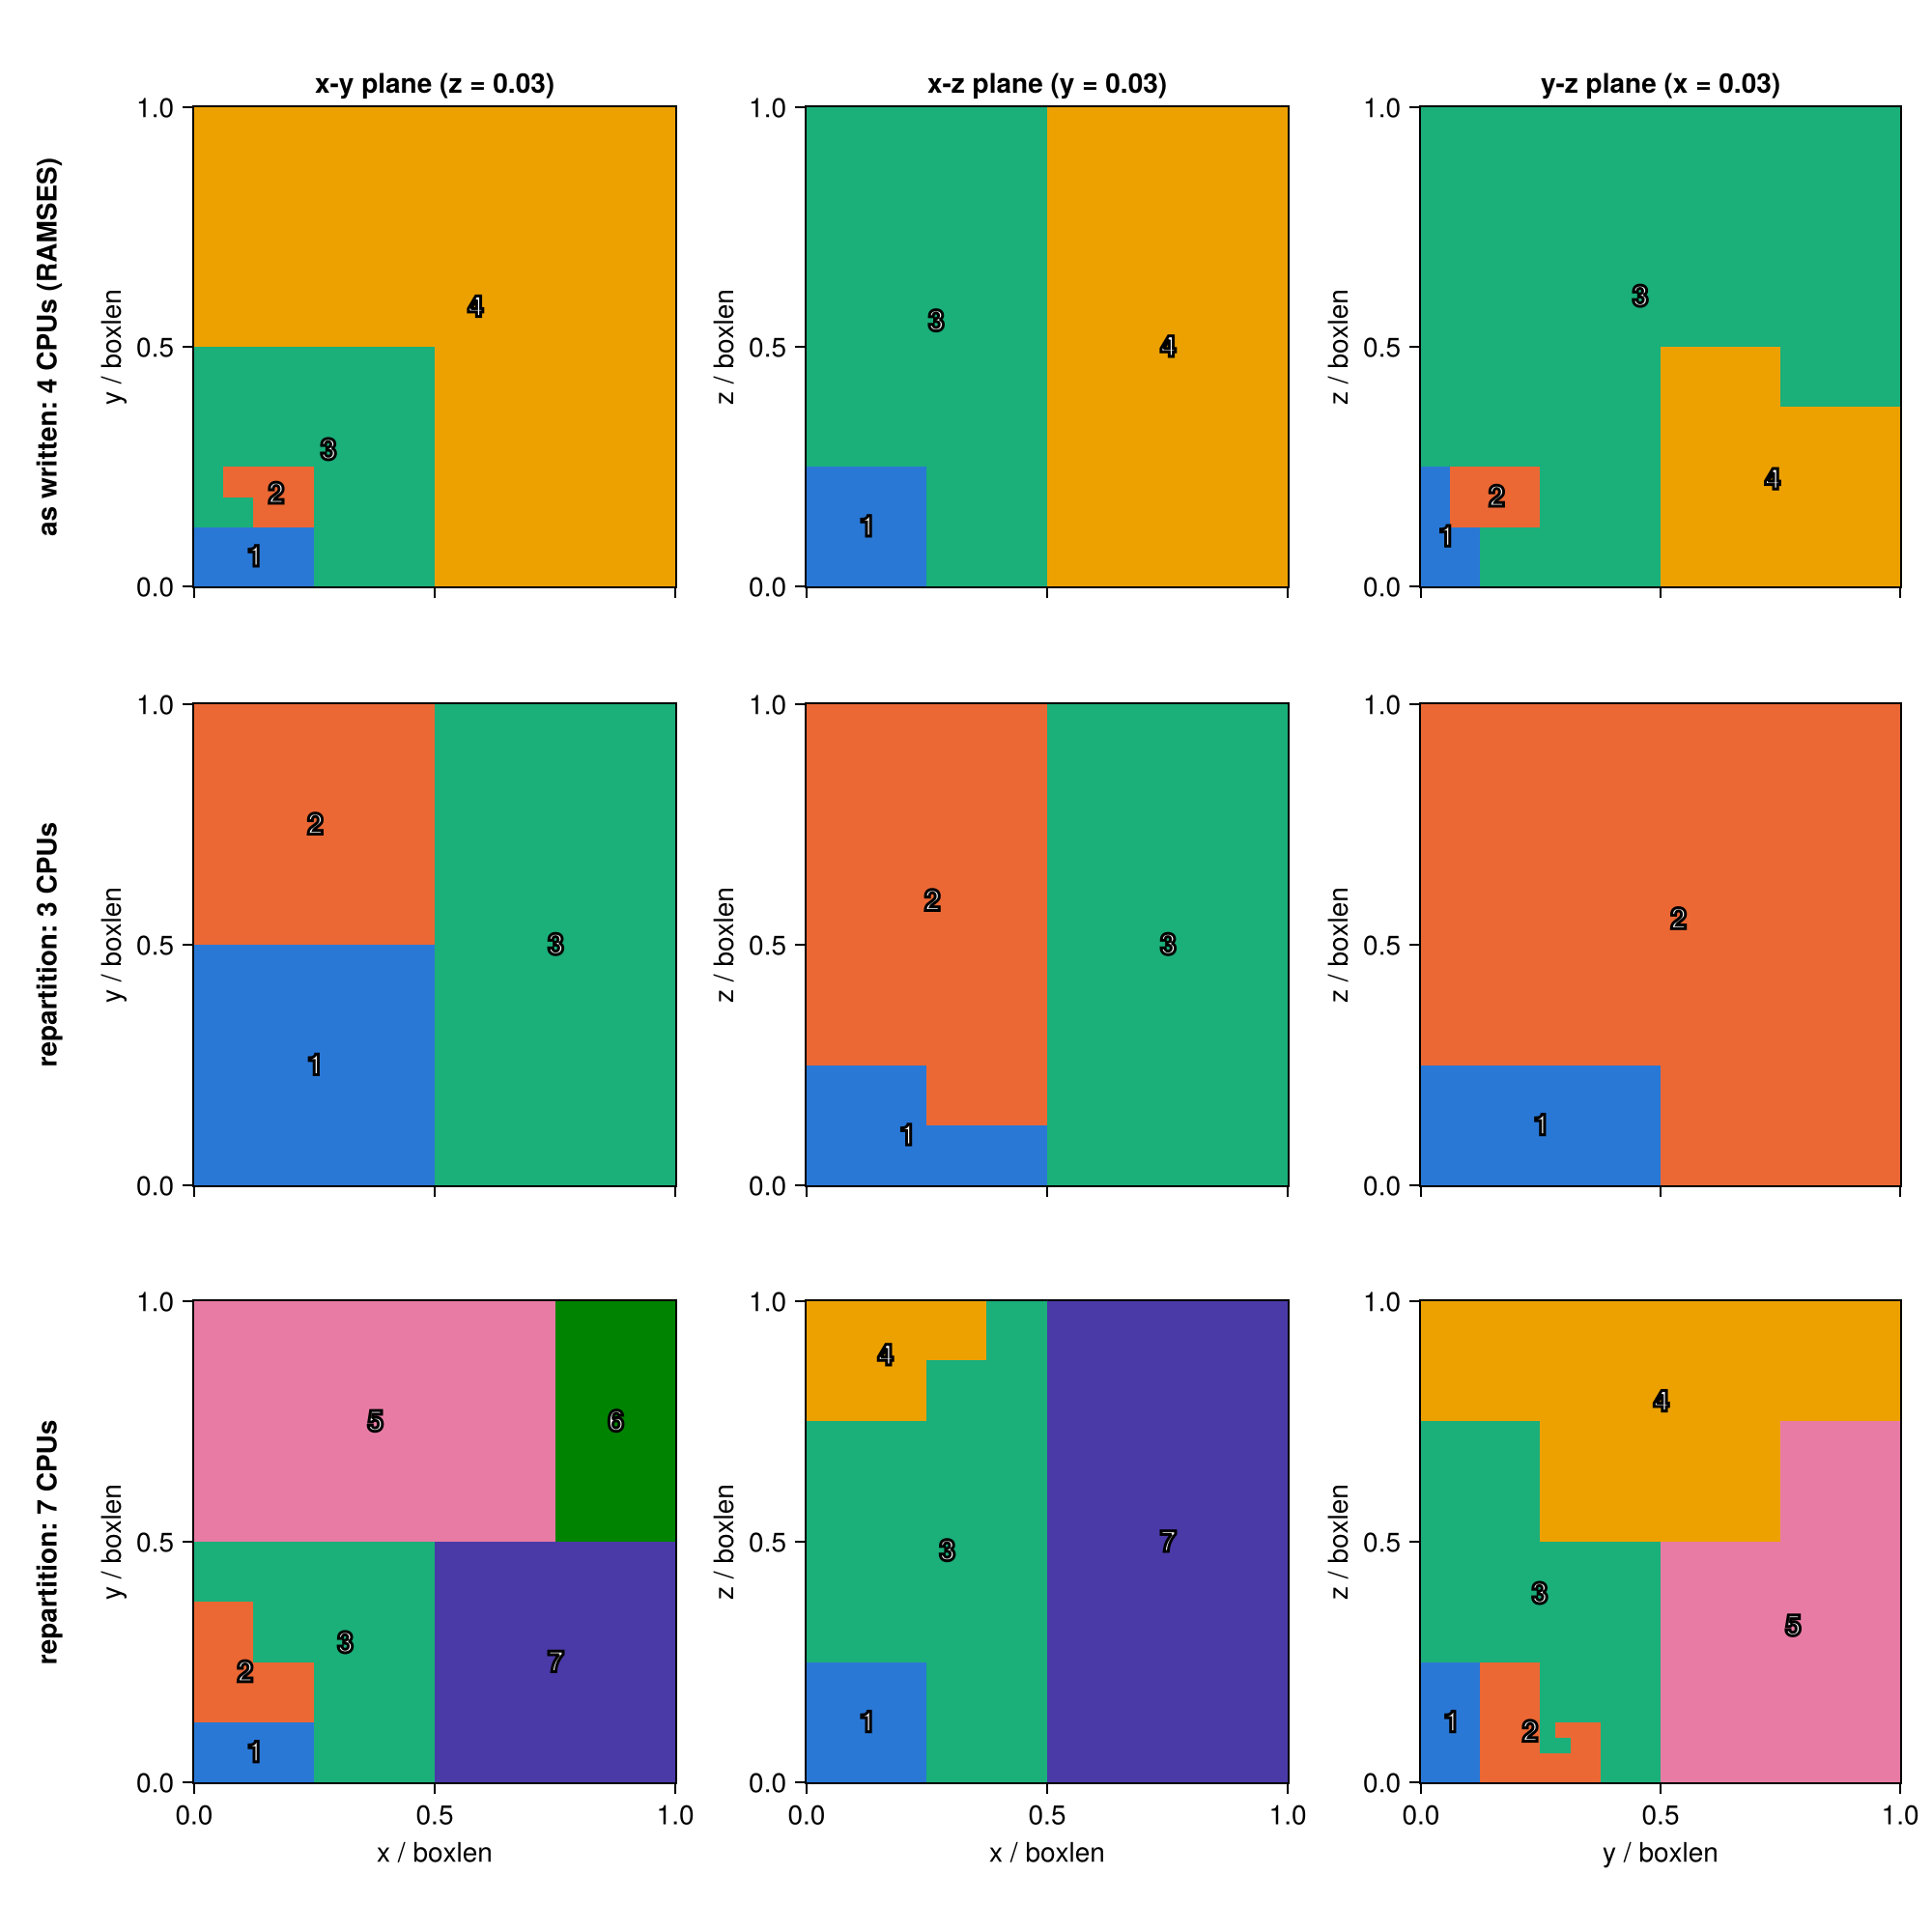

In [4]:
t = RW.read_global_tree(joinpath(SEDOV, "output_00006"), 6; verbose=false)
n, z = 256, 0.03                 # 0.03: just inside the box faces that meet at the blast
decs = [(4, "as written: 4 CPUs (RAMSES)", RW.decompose(t, 4; bound_key=copy(t.header.bound_key))),
        (3, "repartition: 3 CPUs",         RW.decompose(t, 3)),
        (7, "repartition: 7 CPUs",         RW.decompose(t, 7))]
planes = [(3, "x-y plane (z = 0.03)", "x", "y"), (2, "x-z plane (y = 0.03)", "x", "z"),
          (1, "y-z plane (x = 0.03)", "y", "z")]
fig = Figure(size=(1000, 1000))
for (row, (ncpu, name, dec)) in enumerate(decs), (col, (axis, pname, xl, yl)) in enumerate(planes)
    img = slice_map(t, z, n, (l, g, ind) -> Float64(dec.cpu_map[l][g, ind]); axis=axis)
    ax = Axis(fig[row, col]; aspect=DataAspect(), title = row == 1 ? pname : "",
              xlabel = row == 3 ? "$xl / boxlen" : "", ylabel = "$yl / boxlen",
              xticklabelsvisible = row == 3)
    heatmap!(ax, range(0, 1; length=n), range(0, 1; length=n), img;
             colormap=cgrad(CPU_COLORS[1:ncpu]; categorical=true), colorrange=(0.5, ncpu + 0.5))
    label_ranks!(ax, img, n)
    col == 1 && Label(fig[row, 0], name; rotation=π/2, font=:bold, tellheight=false)
end
fig

as written: 4 CPUs (RAMSES)  cells per rank [1050, 1056, 2621, 3353]   (max/min 3.193)
repartition: 3 CPUs          cells per rank [2693, 2693, 2694]   (max/min 1.000)


repartition: 7 CPUs          cells per rank [1154, 1154, 1154, 1155, 1154, 1154, 1155]   (max/min 1.001)


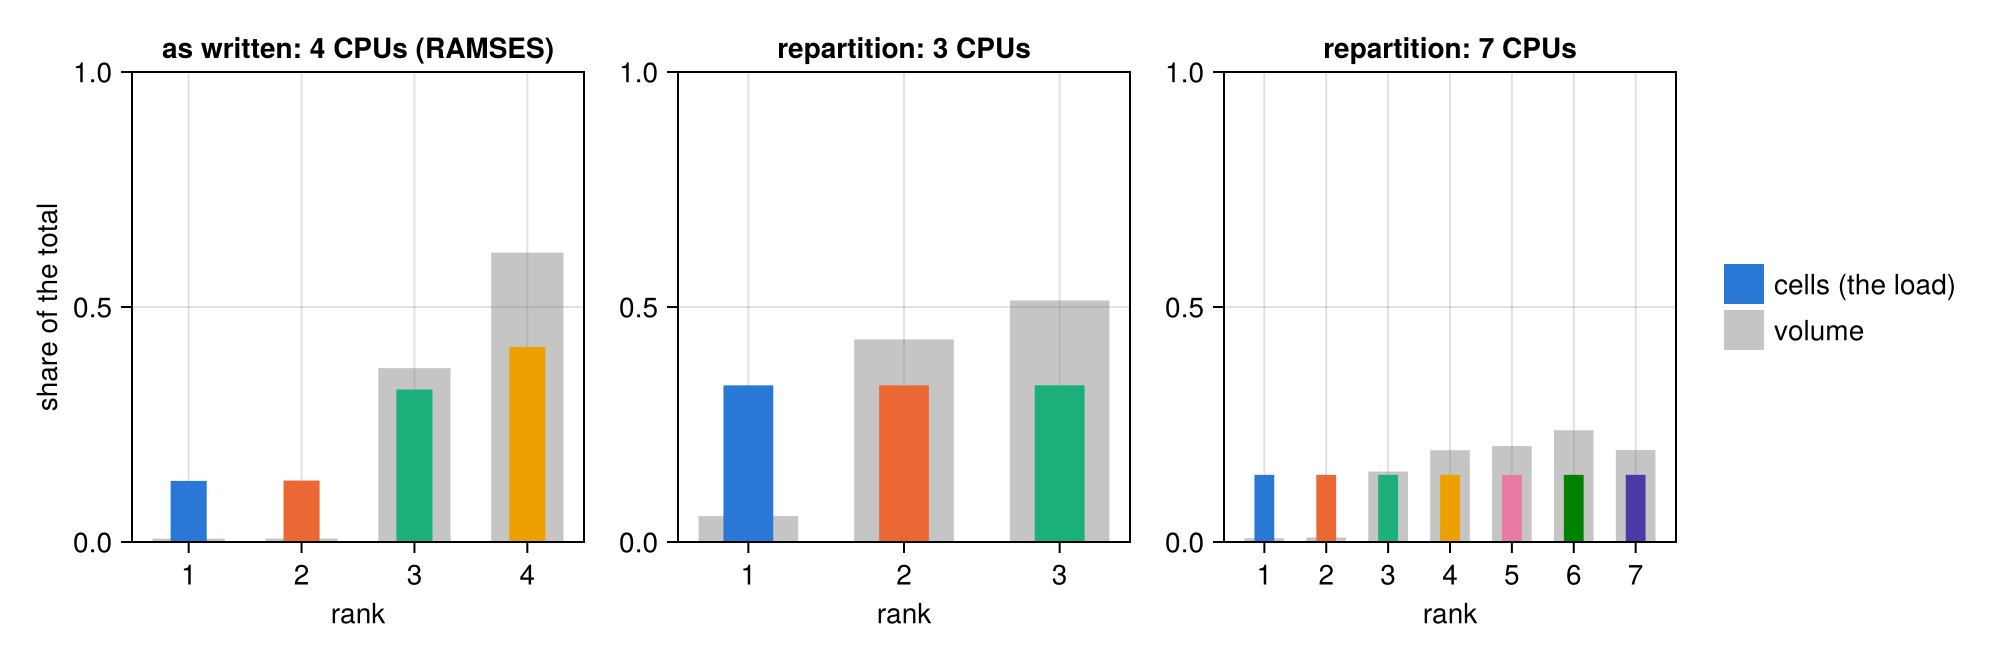

In [5]:
# The load behind those shapes: cells owned per rank, counted on every level (the unit RAMSES and
# repartition balance), and each rank's share of the box VOLUME, measured on its leaf cells.
leaves = leaf_cells(t)
fig = Figure(size=(1000, 330))
for (col, (ncpu, name, dec)) in enumerate(decs)
    cells  = [sum(count(==(k), dec.cpu_map[l]) for l in 1:RW.nlevels(t)) for k in 1:ncpu]
    volume = [sum(c.dx^3 for c in leaves if dec.cpu_map[c.l][c.g, c.ind] == k; init=0.0) for k in 1:ncpu]
    ax = Axis(fig[1, col]; title=name, xlabel="rank", ylabel = col == 1 ? "share of the total" : "",
              xticks=1:ncpu, limits=(nothing, (0, 1)))
    barplot!(ax, 1:ncpu, volume; width=0.8, color=(:gray, 0.45))                  # wide, behind
    barplot!(ax, 1:ncpu, cells ./ sum(cells); width=0.4, color=CPU_COLORS[1:ncpu])  # narrow, in front
    @printf("%-28s cells per rank %s   (max/min %.3f)\n", name, string(cells), maximum(cells) / minimum(cells))
end
Legend(fig[1, 4], [PolyElement(color=CPU_COLORS[1]), PolyElement(color=(:gray, 0.45))],
       ["cells (the load)", "volume"]; framevisible=false)
fig

Narrow coloured bars, cells: after `repartition` every rank holds the same number of cells, to within one.
RAMSES's own split is uneven (1,050 to 3,353 cells): it rebalances only every `nremap` steps, with
its own cost function, and will rebalance the converted run the same way. Wide grey bars, volume: the
volume per rank differs a lot.

The cosmological test run at a = 0.2, split for 16 ranks in both orderings Mera writes (section 10).
Left: the refinement level in a slice through the finest cells. Middle: Hilbert domains, pieces of
one curve that interlock. Right: bisection domains, boxes cut along x, y and z in turn. Domains are
small where the cells are fine:


16 ranks, Hilbert    cells per rank 11871 to 11872
16 ranks, bisection  cells per rank 11278 to 12363


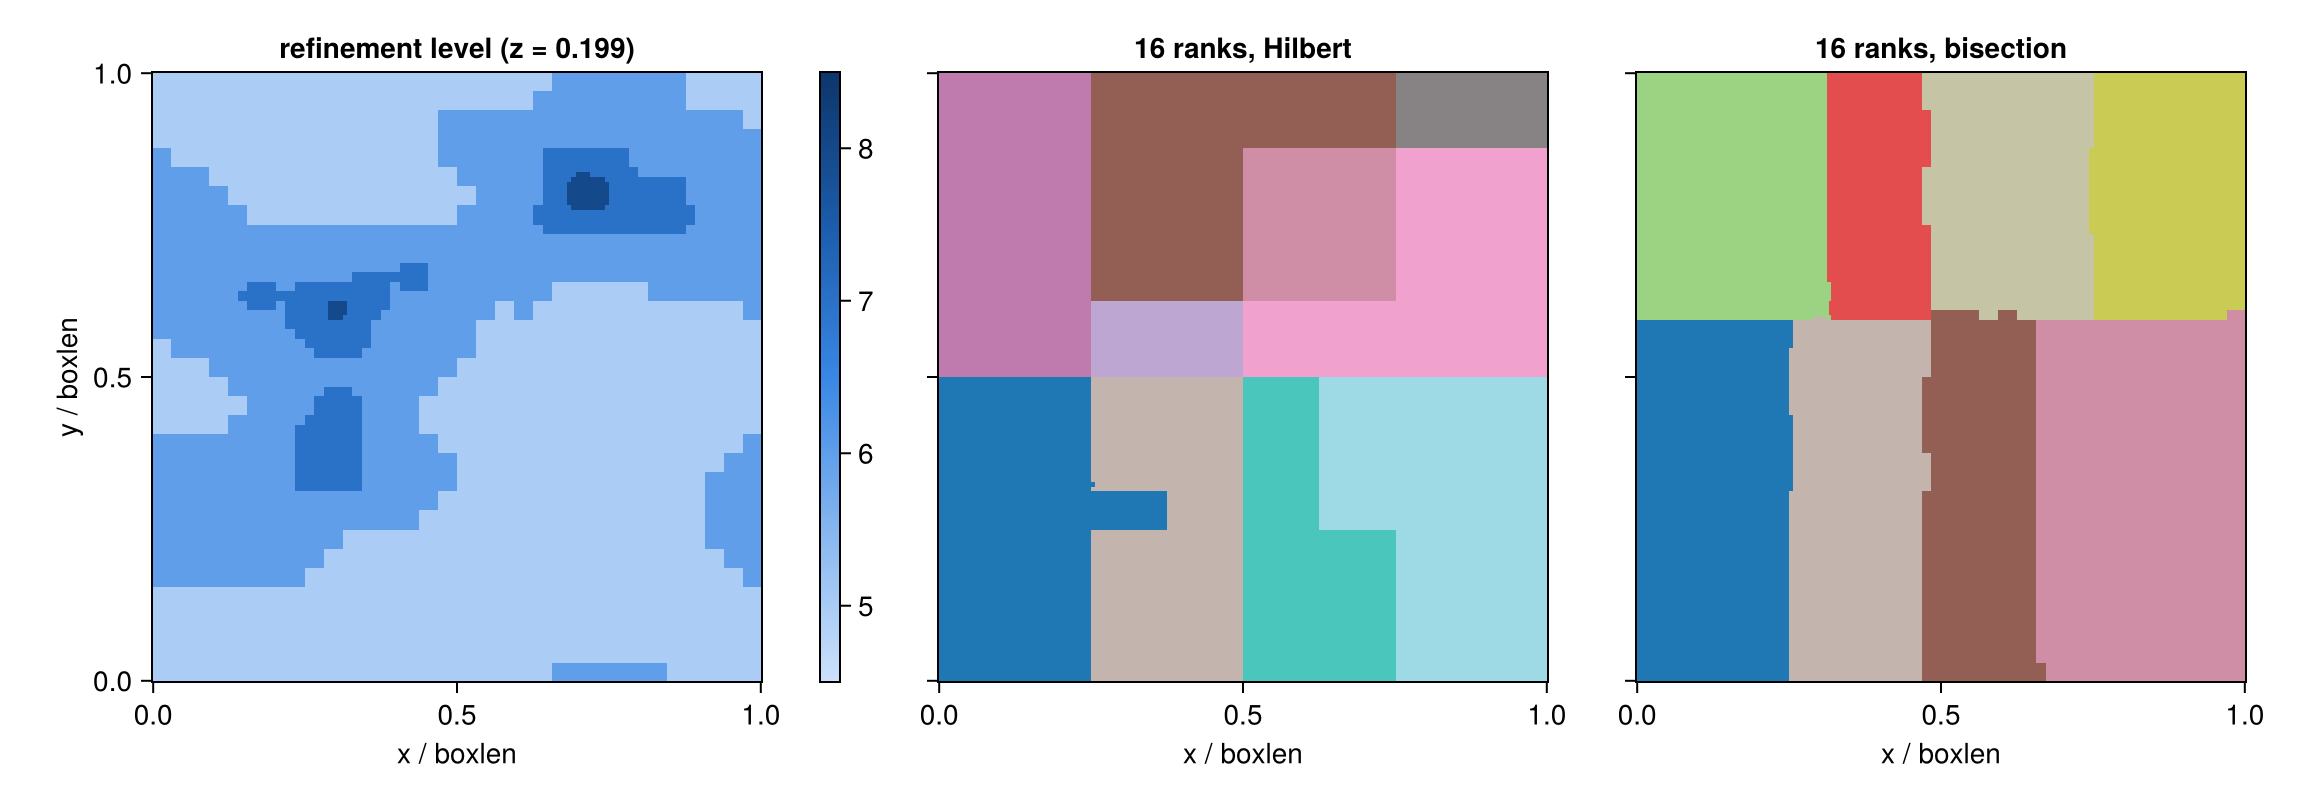

In [6]:
COSMO3D = joinpath(RUNS, "cosmo3d_ncpu8")       # the cosmological test run, 8 CPUs, AMR levels 5 to 8
tc = RW.read_global_tree(joinpath(COSMO3D, "output_00004"), 4; verbose=false)    # a = 0.2
dh, db = RW.new_decomposition(tc, 16; ordering=:hilbert), RW.new_decomposition(tc, 16; ordering=:bisection)
# the slice goes through the finest cells: the middle of the deepest level's grids
deep = tc.levels[end].ig
zc = (sort([Int(g[3]) for g in deep])[cld(length(deep), 2)] + 0.5) / 2.0^(RW.nlevels(tc) - 1)
lev = slice_map(tc, zc, n, (l, g, ind) -> Float64(l))
rk(dec) = slice_map(tc, zc, n, (l, g, ind) -> Float64(dec.cpu_map[l][g, ind]))
fig = Figure(size=(1150, 400))
ax = Axis(fig[1, 1]; aspect=DataAspect(), title=@sprintf("refinement level (z = %.3f)", zc), xlabel="x / boxlen", ylabel="y / boxlen")
hm = heatmap!(ax, range(0, 1; length=n), range(0, 1; length=n), lev; colormap=blues, colorrange=(4.5, 8.5))
Colorbar(fig[1, 2], hm; ticks=5:8, width=10)
for (col, (dec, name)) in enumerate(((dh, "16 ranks, Hilbert"), (db, "16 ranks, bisection")))
    ax = Axis(fig[1, col + 2]; aspect=DataAspect(), title=name, xlabel="x / boxlen", yticklabelsvisible=false)
    heatmap!(ax, range(0, 1; length=n), range(0, 1; length=n), rk(dec);
             colormap=cgrad(:tab20, 16; categorical=true), colorrange=(0.5, 16.5))
    cells = [sum(count(==(k), dec.cpu_map[l]) for l in 1:RW.nlevels(tc)) for k in 1:16]
    @printf("%-20s cells per rank %d to %d\n", name, minimum(cells), maximum(cells))
end
fig

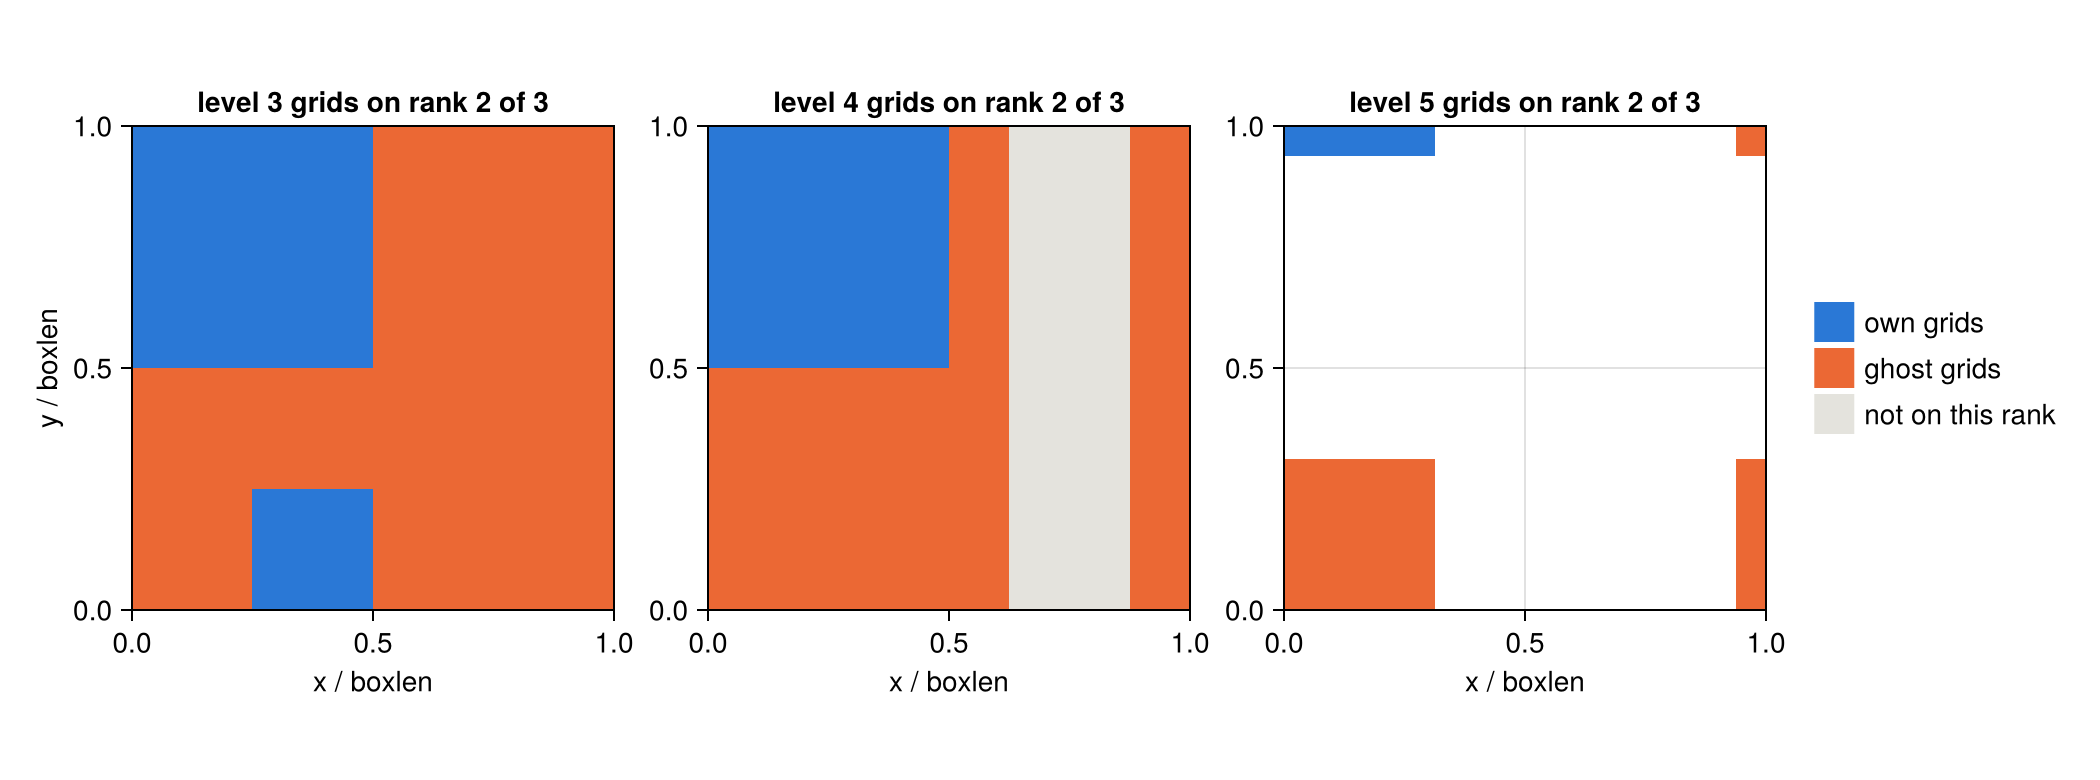

In [7]:
# The grids rank 2 of 3 holds on levels 3, 4 and 5: its own and the ghost grids around them.
# The slice is the x-y plane at z = 0.03, just inside the bottom face, through the blast.
dec3 = RW.decompose(t, 3)
rank_grids_figure(t, dec3, 2, (3, 4, 5); z=0.03)


A slice at z = 0.03, through the blast. Blue: the grids rank 2 owns. Orange: **ghost grids**, copies of its neighbours' grids next to its
border, because the solver needs the neighbouring values. The ghost layer is one grid wide. On these
coarse levels one grid is a large part of the box (a quarter of it at level 3), so the ghosts cover
much of it; each finer level halves the layer. The box is periodic, so the layer continues across
the faces: the orange strip at the right edge of the level-4 panel borders rank 2's cells at the
left edge. White: not refined there.

### Walls

Many runs have walls instead of a periodic box: gas flows out (outflow), bounces back (reflexive) or
flows in with fixed values (imposed). The solver also needs cells beyond a wall, so RAMSES keeps a
layer of **boundary grids** just outside each wall, filled from the cells just inside. These grids
are stored in the files, so `repartition` must build them for every new rank; check 1 (section 4)
tests them. The example is the Sedov run with outflow walls on all six faces, split over 3 ranks.
How many grids each rank holds:


In [8]:
OUTFLOW = joinpath(RUNS, "sedov3d_outflow_ncpu4")     # Sedov run, outflow walls on all six faces
to   = RW.read_global_tree(joinpath(OUTFLOW, "output_00004"), 4; verbose=false)
deco = RW.decompose(to, 3)
println("rank  own grids  ghost grids  boundary grids")
for k in 1:3
    g = grid_counts(to, deco, k)
    @printf("%-5d %-10d %-12d %d\n", k, g.own, g.ghost, g.boundary)
end


rank  own grids  ghost grids  boundary grids
1     32539      2998         3246
2     32538      3190         3194


3     32540      2997         3246


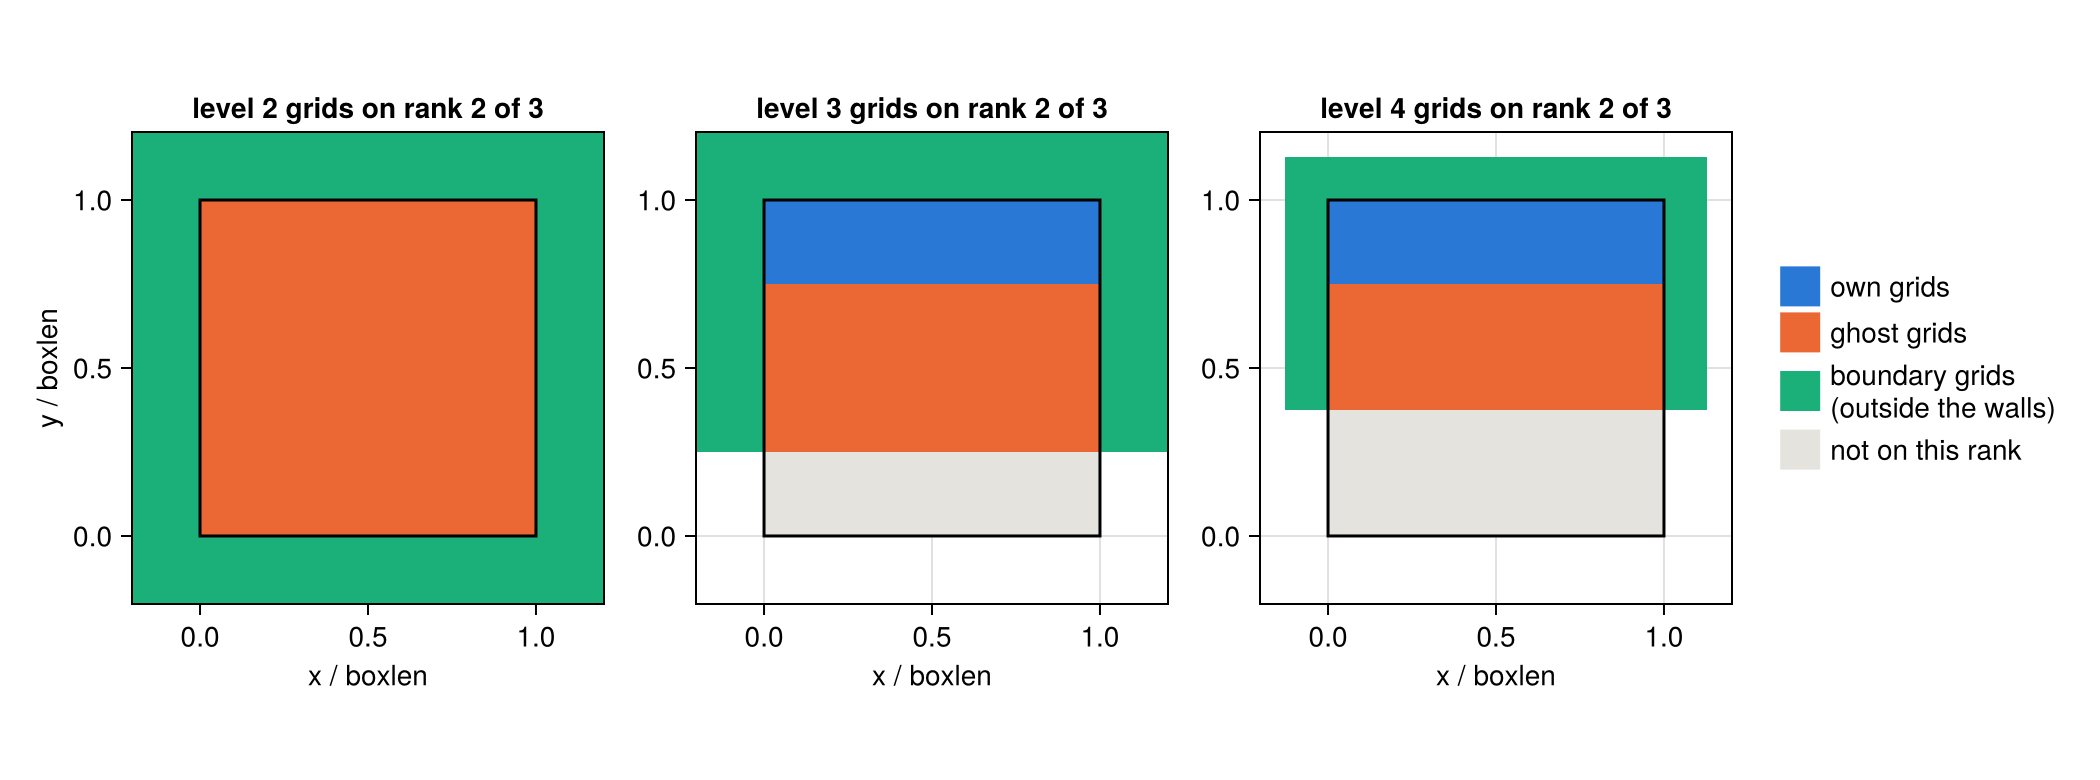

In [9]:
# Rank 2 around the box, levels 2 to 4, in the x-y plane through the box centre (z = 0.5)
rank_grids_figure(to, deco, 2, (2, 3, 4); z=0.5, xs=range(-0.2, 1.2; length=280), walls=true)


The black square is the box. Green: the boundary grids rank 2 holds, outside the walls next to its
own and ghost grids. On level 2 one grid is half the box, so rank 2 holds every grid there as a
ghost. On finer levels it owns the top of the box (blue), and the green layer gets thinner, since
each grid is half as wide. White: no grid there. Ghosts are about 9 % of a rank's grids here,
because most grids are on finer levels.

## 3. `repartition`: what it does, step by step

| step | what | how | why |
|---|---|---|---|
| 1 | read the global octree | every old `amr_*` file | the new split needs the whole tree |
| 2 | new domains | Hilbert curve cut into `ncpu` pieces of equal work (cells, plus particles with `balance_particles=true`) | equal load; no rank exceeds `npartmax` |
| 3 | each rank's octree | own + ghost + boundary grids, with every pointer | this is what RAMSES loads |
| 4 | cell files | `hydro_*`, `grav_*`, `rt_*` values copied bit for bit | nothing is recomputed |
| 5 | particles and text files | each particle to the rank of its cell; clump rows re-dealt; `info_*.txt` gets the new domains; other files copied | the rest of the output |


In [10]:
rep = repartition(6, SEDOV, 3; outpath=joinpath(WORK, "sedov_3cpu"));

[1/5] reading the octree of output_00006


  reading amr file 4 / 4
      1010 grids on 7 levels, ncpu = 4, periodic box, nexpand_bound = 1
[2/5] hilbert decomposition for 3 ranks
[3/5] building the local octree of every rank


[4/5] writing amr / hydro / grav / rt files


[5/5] particles, clump tables and text files
RAMSES output repartitioned: ncpu 4 → 3


  from : /Volumes/FASTStorage/projects/RamsesConverter/testruns/sedov3d_amr_lb_ncpu4/output_00006
  to   : /var/folders/k5/gw4hqgwj5_qf8sljz0091x1m0000gp/T/jl_KQM620/sedov_3cpu/output_00006
  own grids per rank      : min 335, max 338
  grids in memory per rank: min 592, max 673  (own + ghost + boundary)
  restart namelist needs  : ngridmax ≥ 674
  14 files written in 0.7 s


The report's last line goes into the restart namelist: `ngridmax` (and `npartmax`) per rank. Fewer
ranks need more per rank.

## 4. Check 1: same files as RAMSES

This check changes nothing: same output, same 4 ranks, same domain walls as RAMSES. Mera writes the
four amr files (one per rank) again with its own writer and compares them with the files RAMSES
wrote. If they match, the writer builds each rank's tree (own grids, ghosts, pointers) exactly as
RAMSES does, and the same code then builds the files for other rank counts.

Grids are matched by level and position, pointers by what they point to, so a different numbering
does not count as a difference. Grids, ghosts, boundary grids, pointers and the counts per level
must all match.


In [11]:
# Every grid named by (level, list, position); every pointer by the position it points to.
function canonical_amr(path)
    h, lists = RW.read_amr_file(path)
    L = Int(h.nlevelmax); ncoarse = Int(h.nx * h.ny * h.nz); ngm = Int(h.ngridmax)
    where = Dict{Int32,Tuple{Int,RW.Coord}}()
    for l in 1:L, g in lists[l], i in 1:RW.ngrids(g)
        where[g.ind_grid[i]] = (l, RW.grid_coord(view(g.xg, i, :), l))
    end
    cellc(p) = p == 0 ? nothing : p <= ncoarse ? (0, p) :
               (ind = (p - ncoarse - 1) ÷ ngm + 1; ig = p - ncoarse - (ind - 1) * ngm;
                haskey(where, ig) ? (where[ig]..., ind) : (:dangling, ig))
    gridc(p) = p == 0 ? nothing : get(where, p, (:dangling, p))
    out = Dict(f => Set() for f in (:grids, :father, :nbor, :son, :cpu_map))
    for l in 1:L, (ib, g) in enumerate(lists[l]), i in 1:RW.ngrids(g)
        key = (l, ib, RW.grid_coord(view(g.xg, i, :), l))
        push!(out[:grids], key)
        push!(out[:father], (key, cellc(g.father[i])))
        push!(out[:nbor], (key, Tuple(cellc(x) for x in g.nbor[i, :])))
        push!(out[:son], (key, Tuple(gridc(x) for x in g.son[i, :])))
        push!(out[:cpu_map], (key, Tuple(g.cpu_map[i, :])))
    end
    out
end

src = joinpath(SEDOV, "output_00006")
dec4 = RW.decompose(t, 4; bound_key=copy(t.header.bound_key))
nexp = RW.detect_nexpand_bound(src)
lts  = [RW.build_local_tree(t, dec4, k; nexpand_bound=nexp) for k in 1:4]
nt   = RW.global_numbtot([l.numbl for l in lts], t.header.nlevelmax)
umt  = maximum(RW.ngrid_current, lts)
println(rpad("rank", 6), rpad("grids", 8), rpad("grids", 8), rpad("fathers", 9), rpad("neighbours", 12),
        rpad("children", 10), "owners")
for k in 1:4
    tmp = tempname()
    RW.write_amr_file(tmp, RW.amr_file_content(t, dec4, lts[k], Int(t.header.ngridmax), nt, umt)...)
    a, b = canonical_amr(RW.amr_filename(src, 6, k)), canonical_amr(tmp)
    println(rpad(k, 6), rpad(length(a[:grids]), 8), rpad(ok_mark(a[:grids] == b[:grids]), 8),
            rpad(ok_mark(a[:father] == b[:father]), 9), rpad(ok_mark(a[:nbor] == b[:nbor]), 12),
            rpad(ok_mark(a[:son] == b[:son]), 10), ok_mark(a[:cpu_map] == b[:cpu_map]))
    rm(tmp)
end

rank  grids   

grids   fathers  neighbours  children  owners
1     383     

yes     yes      yes         yes       yes
2     468     

yes     yes      yes         yes       yes
3     752     yes     yes      yes         yes       yes
4     705     

yes     yes      yes         yes       yes


The same on the run with outflow walls, boundary grids included:


In [12]:
srco = joinpath(OUTFLOW, "output_00004")
dec4o = RW.decompose(to, 4; bound_key=copy(to.header.bound_key))
lto4  = [RW.build_local_tree(to, dec4o, k; nexpand_bound=RW.detect_nexpand_bound(srco)) for k in 1:4]
nto   = RW.global_numbtot([l.numbl for l in lto4], to.header.nlevelmax)
umto  = maximum(RW.ngrid_current, lto4)
println(rpad("rank", 6), rpad("grids", 8), rpad("boundary", 10), rpad("grids", 8), rpad("fathers", 9),
        rpad("neighbours", 12), rpad("children", 10), "owners")
for k in 1:4
    tmp = tempname()
    RW.write_amr_file(tmp, RW.amr_file_content(to, dec4o, lto4[k], Int(to.header.ngridmax), nto, umto)...)
    a, b = canonical_amr(RW.amr_filename(srco, 4, k)), canonical_amr(tmp)
    nb = count(key -> key[2] > 4, a[:grids])                   # lists beyond the 4 CPU lists: walls
    println(rpad(k, 6), rpad(length(a[:grids]), 8), rpad(nb, 10), rpad(ok_mark(a[:grids] == b[:grids]), 8),
            rpad(ok_mark(a[:father] == b[:father]), 9), rpad(ok_mark(a[:nbor] == b[:nbor]), 12),
            rpad(ok_mark(a[:son] == b[:son]), 10), ok_mark(a[:cpu_map] == b[:cpu_map]))
    rm(tmp)
end

rank  grids   

boundary  grids   fathers  neighbours  children  owners
1     

29097   2490      yes     yes      yes         yes       yes
2     29097   

2490      yes     yes      yes         yes       yes
3     

29097   2490      yes     yes      yes         yes       yes
4     29027   

2450      yes     yes      yes         yes       yes


Every rank is rebuilt exactly. The same holds for every run of the RAMSES validation suite, a
16-level cosmological run on 16 CPUs and a galaxy run on 640 CPUs. New splits come from the same
code, so they are what RAMSES would write.

## 5. Check 2: same values

[`compareramses`](@ref) compares two outputs with any rank counts: the octree, every hydro, gravity
and RT value (relative to the variable's largest value) and every particle, matched by identity. A
conversion, and a round trip, must give exactly zero:


In [13]:
println(rpad("conversion", 22), rpad("same octree", 13), rpad("max |Δ| hydro", 15), "particles, max |Δx|")
for (label, a, b, ncpu) in (("4 → 1",     SEDOV, nothing, 1), ("4 → 3", SEDOV, nothing, 3),
                           ("4 → 7",     SEDOV, nothing, 7), ("4 → 8", SEDOV, nothing, 8),
                           ("dm_gas 4 → 7", DMGAS, nothing, 7))
    o   = a == DMGAS ? 4 : 6
    out = joinpath(WORK, "check2_" * replace(label, r"\W+" => "_"))
    repartition(o, a, ncpu; outpath=out, verbose=false)
    c = compareramses(o, a, out)
    println(rpad(label, 22), rpad(ok_mark(c.same_tree), 13), rpad(@sprintf("%.1e", maximum(c.maxdiff["hydro"])), 15),
            c.nparticles[1], ", ", @sprintf("%.1e", c.particle_maxdiff[1]))
end
# and back: 4 → 3 → 4 must be the original, file by file in content
repartition(6, joinpath(WORK, "sedov_3cpu"), 4; outpath=joinpath(WORK, "sedov_back"), verbose=false)
c = compareramses(6, SEDOV, joinpath(WORK, "sedov_back"))
println(rpad("4 → 3 → 4", 22), rpad(ok_mark(c.same_tree), 13), @sprintf("%.1e", maximum(c.maxdiff["hydro"])))

conversion            same octree  max |Δ| hydro  particles, max |Δx|


4 → 1                 yes          0.0e+00        0, 0.0e+00
4 → 3                 yes          0.0e+00        0, 0.0e+00


4 → 7                 yes          0.0e+00        0, 0.0e+00
4 → 8                 yes          0.0e+00        0, 0.0e+00


dm_gas 4 → 7          yes          0.0e+00        30000, 0.0e+00
4 → 3 → 4             yes          0.0e+00


All zero: the values are copied, never recomputed.

## 6. Check 3: same data in RAMSES

RAMSES rebuilds ghost zones and communication tables when it reads files, so a wrong pointer would
show only there. The test: RAMSES reads the files and writes its memory out **before any step**,
once from the converted files and once from the originals on 4 ranks. The two dumps are compared.

RAMSES has no switch for this: after a restart it refuses to write before its first step (one test
in `amr/output_amr.f90`). The dumps come from a RAMSES build with that one line disabled, run with
`nstepmax` one step ahead and `foutput=1`.


In [14]:
# nstep_coarse of the restart output: nstepmax one ahead makes RAMSES stop after that dump
nstep = Int(RW.read_amr_file(RW.amr_filename(joinpath(SEDOV, "output_00006"), 6, 1))[1].nstep_coarse)
function readback_dump(src_run, ncpu, name; ngridmax=20_000)
    d = mkpath(joinpath(WORK, name))
    isdir(joinpath(d, "output_00006")) || cp(joinpath(src_run, "output_00006"), joinpath(d, "output_00006"))
    restart_namelist(joinpath(SEDOV, "sedov3d_amr_lb.nml"), joinpath(d, "run.nml"); ngridmax=ngridmax,
                     run_extra="nstepmax=$(nstep + 1)", output_extra="foutput=1")
    ok = run_ramses(d, "run.nml", 6, ncpu; bin=RAMSES_READBACK)
    return ok ? joinpath(d, "output_00007") : nothing
end
ref = readback_dump(SEDOV, 4, "readback_original_4cpu")                    # original files, 4 ranks
println(rpad("ranks", 8), rpad("same time", 11), rpad("same octree", 13), "every value identical")
for ncpu in (1, 3, 7, 8)
    conv = joinpath(WORK, "readback_conv_$(ncpu)cpu")
    r = repartition(6, SEDOV, ncpu; outpath=conv, overwrite=true, verbose=false)
    dump = readback_dump(conv, ncpu, "readback_conv_$(ncpu)cpu"; ngridmax=max(20_000, 2 * r.ngridmax_needed))
    same_time = readlines(joinpath(ref, "info_00007.txt"))[[6, 9]] == readlines(joinpath(dump, "info_00007.txt"))[[6, 9]]   # nstep_coarse, time
    c = compareramses(7, dirname(ref), dirname(dump))
    println(rpad(ncpu, 8), rpad(ok_mark(same_time), 11), rpad(ok_mark(c.same_tree), 13),
            ok_mark(all(v -> all(iszero, v), values(c.maxdiff))))
end

ranks   same time  same octree  every value identical


1       yes        yes          yes


3       yes        yes          yes


7       yes        yes          yes


8       yes        yes          yes


Identical, bit for bit, for every rank count. The RAMSES validation suite ran the same test on all
13 kinds of run (particles, sinks, MHD, RT) on 1 to 8 ranks, particle and sink records included:


In [15]:
# the suite's result file: one header line, then one run per line
function readsuite(file)
    lines = readlines(joinpath(SUITE, file))
    hdr = split(lines[1], ',')
    parsecell(s) = (s = strip(s, '"'); s == "true" ? true : s == "false" ? false :
                    something(tryparse(Float64, s), s))
    [Dict(zip(hdr, parsecell.(split(l, ',')))) for l in lines[2:end]]
end
fmt(x) = x isa Number && !isnan(x) ? @sprintf("%.0e", x) : "–"
rb = readsuite("readback.csv")
println(rpad("run", 26), "ranks 1 to 8: bit-identical dump")
for run in unique(r["run"] for r in rb)
    rs = [r for r in rb if r["run"] == run]
    println(rpad(run, 26), join((r["bit_identical"] ? "✔" : "✘" for r in sort(rs; by=r -> r["ncpu"])), " "))
end
println("\n", count(r -> r["bit_identical"], rb), " of ", length(rb), " dumps bit-identical")

run                       ranks 1 to 8: bit-identical dump


sedov3d_amr_lb_ncpu4      

✔ ✔ ✔ ✔ ✔ ✔ ✔ ✔
sedov3d_amr_lb_ncpu8      ✔ ✔ ✔ ✔ ✔ ✔ ✔ ✔
sedov3d_amr_ncpu1         ✔ ✔ ✔ ✔ ✔ ✔ ✔ ✔
sedov3d_amr_ncpu3         ✔ ✔ ✔ ✔ ✔ ✔ ✔ ✔
sedov3d_uniform_ncpu4     ✔ ✔ ✔ ✔ ✔ ✔ ✔ ✔
sedov3d_outflow_ncpu4     ✔ ✔ ✔ ✔ ✔ ✔ ✔ ✔
dm_gas3d_ncpu4            ✔ ✔ ✔ ✔ ✔ ✔ ✔ ✔
sedov3d_grav_part_ncpu4   ✔ ✔ ✔ ✔ ✔ ✔ ✔ ✔
starform3d_ncpu4          ✔ ✔ ✔ ✔ ✔ ✔ ✔ ✔
sinks3d_ncpu4             ✔ ✔ ✔ ✔ ✔ ✔ ✔ ✔
clumps3d_ncpu4            ✔ ✔ ✔ ✔ ✔ ✔ ✔ ✔
mhdtube3d_ncpu4           ✔ ✔ ✔ ✔ ✔ ✔ ✔ ✔
stromgren3d_ncpu4         ✔ ✔ ✔ ✔ ✔ ✔ ✔ ✔

104 of 104 dumps bit-identical


## 7. Check 4: same evolution

Two runs from output 6: RAMSES's own restart on 4 ranks, and the converted files on 3 ranks. Both
run to output 7 (13 steps) and are compared there. Had RAMSES read anything wrong, they would drift
apart.

They cannot agree to the last digit, for two reasons inside RAMSES:

- **Order of additions.** RAMSES adds up numbers from all ranks, for example to find the time step
  and in the gravity solver. On 3 ranks it adds them in another order than on 4, and in computer
  arithmetic the order can change the last digit.
- **Conversion on reading.** The files store velocity and pressure, but RAMSES computes with
  momentum and energy. When it reads a restart, it converts back, and that can change the last
  digit too.

The end of this section shows how large these differences are when RAMSES restarts itself, without
Mera.


In [16]:
# the converted output, in its own run directory, with a namelist sized for 3 ranks
run3 = joinpath(WORK, "sedov_3cpu")
restart_namelist(joinpath(SEDOV, "sedov3d_amr_lb.nml"), joinpath(run3, "run.nml");
                 ngridmax=max(20_000, round(Int, 1.3 * rep.ngridmax_needed)))
println("RAMSES on 3 ranks finished: ", run_ramses(run3, "run.nml", 6, 3))

native = joinpath(RUNS, "sedov3d_amr_lb_ncpu4_restart")   # RAMSES's own restart on 4 ranks
c = compareramses(7, native, run3)
println("same octree after one output: ", c.same_tree)
println(@sprintf("largest difference, every hydro variable: %.1e", maximum(c.maxdiff["hydro"])))

RAMSES on 3 ranks finished: true
same octree after one output: true
largest difference, every hydro variable: 7.6e-16


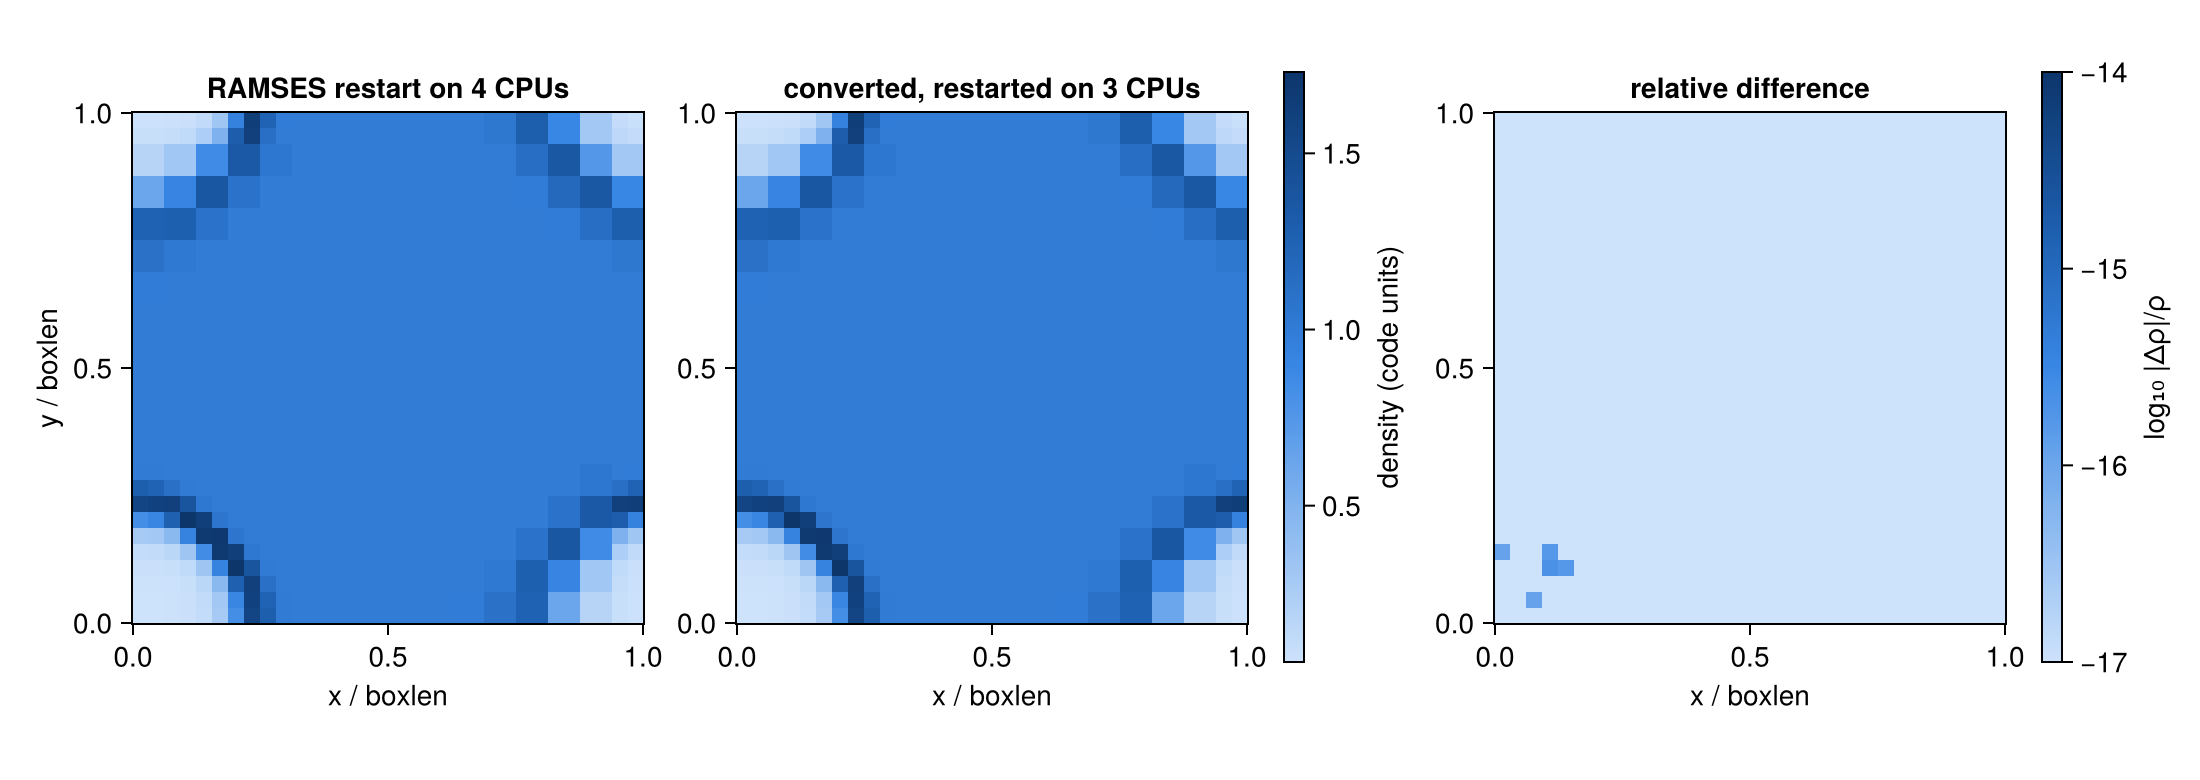

In [17]:
ρn = density_slice(joinpath(native, "output_00007"), 7, z, n)
ρc = density_slice(joinpath(run3,   "output_00007"), 7, z, n)
rel = abs.(ρc .- ρn) ./ abs.(ρn)
fig = Figure(size=(1100, 390))
for (col, (img, ttl)) in enumerate(((ρn, "RAMSES restart on 4 CPUs"), (ρc, "converted, restarted on 3 CPUs")))
    ax = Axis(fig[1, col]; aspect=DataAspect(), title=ttl, xlabel="x / boxlen", ylabel=col == 1 ? "y / boxlen" : "")
    hm = heatmap!(ax, range(0, 1; length=n), range(0, 1; length=n), img; colormap=blues, colorrange=extrema(ρn))
    col == 2 && Colorbar(fig[1, 3], hm; label="density (code units)", width=10)
end
ax = Axis(fig[1, 4]; aspect=DataAspect(), title="relative difference", xlabel="x / boxlen")
hm = heatmap!(ax, range(0, 1; length=n), range(0, 1; length=n), log10.(max.(rel, 1e-17));
              colormap=blues, colorrange=(-17, -14))
Colorbar(fig[1, 5], hm; label="log₁₀ |Δρ|/ρ", width=10)
fig

Machine precision everywhere: RAMSES cannot tell the converted files from its own. Particles are a
stricter test, because gravity couples each particle to all the mass. The run with 30,000
dark-matter particles, converted to 7 ranks:


In [18]:
run7 = joinpath(WORK, "check2_dm_gas_4_7")
r7 = repartition(4, DMGAS, 7; outpath=run7, overwrite=true, verbose=false)
restart_namelist(joinpath(DMGAS, "dm_gas3d.nml"), joinpath(run7, "run.nml");
                 ngridmax=max(20_000, round(Int, 1.3 * r7.ngridmax_needed)),
                 npartmax=max(200_000, 3 * r7.npart_max))
println("RAMSES on 7 ranks finished: ", run_ramses(run7, "run.nml", 4, 7))
c = compareramses(5, joinpath(RUNS, "dm_gas3d_ncpu4_restart"), run7)
println("same octree: ", c.same_tree, ",  particles matched by identity: ", c.nmatched)
println(@sprintf("largest difference: hydro %.1e, gravity %.1e, particle position %.1e boxlen",
                 maximum(c.maxdiff["hydro"]), maximum(c.maxdiff["grav"]), c.particle_maxdiff[1]))

RAMSES on 7 ranks finished: true


same octree: true,  particles matched by identity: 30000
largest difference: hydro 8.5e-15, gravity 1.2e-14, particle position 5.6e-16 boxlen


**RAMSES alone, for comparison:** the Sedov run on 4 and on 8 CPUs from the start, and a restart on
its own 4 CPUs against the same run computed straight through, without a restart:


In [19]:
floorcmp = [("RAMSES from t = 0 on 4 vs 8 CPUs, output 7",
          compareramses(7, SEDOV, joinpath(RUNS, "sedov3d_amr_lb_ncpu8"))),
         ("RAMSES uninterrupted vs restarted, both on 4 CPUs",
          compareramses(7, SEDOV, joinpath(RUNS, "sedov3d_amr_lb_ncpu4_restart"))),
         ("converted to 3 CPUs, restarted, vs RAMSES restart on 4",
          compareramses(7, joinpath(RUNS, "sedov3d_amr_lb_ncpu4_restart"), run3))]
println(rpad("comparison", 58), rpad("octree", 8), "largest hydro difference")
for (name, c) in floorcmp
    println(rpad(name, 58), rpad(c.same_tree ? "same" : "DIFF", 8), @sprintf("%.1e", maximum(c.maxdiff["hydro"])))
end

comparison                                                octree  largest hydro difference
RAMSES from t = 0 on 4 vs 8 CPUs, output 7                same    1.5e-15
RAMSES uninterrupted vs restarted, both on 4 CPUs         same    1.1e-15
converted to 3 CPUs, restarted, vs RAMSES restart on 4    same    7.6e-16


The RAMSES validation suite, every kind of run. The reference is RAMSES's own restart, or the
run computed straight through, without a restart:


In [20]:
println(rpad("run", 28), rpad("CPUs", 8), rpad("octree", 8), rpad("hydro", 8), rpad("grav", 8),
        rpad("rt", 8), "particles |Δx|")
for r in readsuite("restart.csv")
    println(rpad(r["run"], 28), rpad("$(Int(r["ncpu_old"])) → $(Int(r["ncpu_new"]))", 8),
            rpad(r["same_octree"] ? "same" : "DIFF", 8), rpad(fmt(r["hydro"]), 8),
            rpad(fmt(r["grav"]), 8), rpad(fmt(r["rt"]), 8), fmt(r["dx_boxlen"]))
end

run                         CPUs    octree  hydro   grav    rt      particles |Δx|
sedov3d_amr_lb_ncpu4        4 → 3   same    8e-16   –       –       0e+00
sedov3d_amr_lb_ncpu4        4 → 1   same    8e-16   –       –       0e+00
sedov3d_amr_lb_ncpu4        4 → 7   same    8e-16   –       –       0e+00
sedov3d_amr_lb_ncpu8        8 → 5   same    9e-16   –       –       0e+00
sedov3d_amr_ncpu1           1 → 8   same    1e-15   –       –       0e+00
sedov3d_amr_ncpu3           3 → 6   same    1e-15   –       –       0e+00
sedov3d_uniform_ncpu4       4 → 3   same    5e-16   –       –       0e+00
sedov3d_uniform_ncpu4       4 → 7   same    0e+00   –       –       0e+00
sedov3d_outflow_ncpu4       4 → 3   same    6e-15   –       –       0e+00
sedov3d_outflow_ncpu4       4 → 8   same    6e-15   –       –       0e+00
dm_gas3d_ncpu4              4 → 7   same    8e-15   1e-14   –       6e-16
dm_gas3d_ncpu4              4 → 1   same    1e-14   4e-13   –       6e-16
sedov3d_grav_part_ncpu4     4

Same octree and round-off everywhere, except **stochastic star formation** (and Monte-Carlo
tracers): their random seeds depend on the rank count, as when RAMSES itself changes it.
`starform3d` is another random realization, not an error.

## 8. From Mera data and mera files: `writeramses`

Mera keeps the **leaf cells** (the finest cell at each place), the particles and the sinks. A
restart also needs the whole octree, the refined (parent) cells and some header values.
[`writeramses`](@ref) rebuilds them:

| RAMSES needs | Mera has | how |
|---|---|---|
| the octree | leaves with level and position | each leaf implies its ancestors: exact |
| leaf values | all variables | copied |
| refined hydro cells | not stored | average of the 8 children, as RAMSES's `upload_fine` (internal energy for `interpol_var` 1 or 2, else total energy) |
| refined gravity cells | only with `getgravity(info; parents=true)` | written back as RAMSES stored them. With `parents=false` (the default) Mera keeps only the leaves, `writeramses` fills these cells with averages of their children, and RAMSES continues less exactly (gas `5e-5`, below) |
| ghost and boundary grids, pointers | not stored | built as in `repartition` |
| time, time steps per level, energies | `info.grid_info.amr_header` | copied (in mera files since Mera 1.8.0) |

### Is the data complete?

A restart needs every cell, level, variable and particle; a subregion cannot become a restart.
[`restart_completeness`](@ref) checks this from the data itself, and `writeramses` refuses
incomplete data. The key test: the leaves must fill the box exactly, counted in integers. Data
loaded with Mera's `smallr` or `smallc` is refused too, because these floors raise low values while
loading. (The namelist's own `smallr` is a different thing: RAMSES applies it the same way to every
run.)


In [21]:
di   = getinfo(4, DMGAS, verbose=false)
q    = (verbose=false, show_progress=false)
gas  = gethydro(di; q...);  part = getparticles(di; q...)
grav = getgravity(di; parents=true, q...)     # also the gravity of the refined cells, as RAMSES stored it
ok, report = restart_completeness(gas; gravity=grav, particles=part)
println(ok ? "COMPLETE" : "NOT complete")
for (k, v) in report
    println("   ", rpad(k, 18), v)
end

COMPLETE


   hydro variables   ✔ 5 of 5
   hydro levels      ✔ lmin/lmax 5/7, simulation 5/7
   hydro region      ✔ ranges [0.0, 1.0, 0.0, 1.0, 0.0, 1.0]
   no clamping       ✔ smallr 0.0, smallc 0.0
   unique cells      ✔ 52466 cells, 52466 distinct
   no overlap        ✔ 0 leaves have other leaves inside them
   full coverage     ✔ leaves cover 1.000000000000 of the box
   closed octs       ✔ 0 cells of partly filled octs are missing
   levels            ✔ leaf levels (5, 7), levelmin 5
   finite values     ✔ hydro, 5 columns
   positive density  ✔ min ρ = 0.09492952494378508
   gravity cells     ✔ 52466 cells, same as hydro
   gravity finite    ✔ 
   gravity parents   ✔ 7494 refined cells as stored (restart to round-off)
   particle fields   ✔ all 11
   particle count    ✔ 30000 particles, header_*.txt lists 30000
   particle region   ✔ ranges [0.0, 1.0, 0.0, 1.0, 0.0, 1.0]


In [22]:
# What is refused, and which check catches it.
keep = trues(length(gas.data)); keep[1] = false
cases = [("the full data", gas),
         ("a subregion, half the box", subregion(gas, :cuboid, xrange=[0, 0.5], verbose=false)),
         ("levels up to levelmax - 1", gethydro(di; lmax=di.levelmax - 1, q...)),
         ("density only", gethydro(di, [:rho]; q...)),
         ("one cell removed", Mera._copy_with_data(gas, Mera._subset_table_keyed(gas.data, keep)))]
println(rpad("data", 30), rpad("complete", 10), "failed checks")
for (name, h) in cases
    okc, rp = restart_completeness(h; gravity=grav, particles=part)
    failed = [k for (k, v) in rp if startswith(v, "✘")]
    println(rpad(name, 30), rpad(ok_mark(okc), 10), isempty(failed) ? "–" : join(failed, ", "))
end

data                          complete  

failed checks
the full data                 yes       –
a subregion, half the box     NO        hydro region, full coverage, gravity cells
levels up to levelmax - 1     NO        hydro levels, gravity cells
density only                  NO        

hydro variables


one cell removed              NO        

full coverage, gravity cells


### Through a mera file, back to RAMSES

Save the complete data as a mera file, load it again, write it for 3 CPUs. The leaves must equal the
original, the rebuilt hydro parents must equal RAMSES's, and the gravity parents come from the file:


In [23]:
mf = mkpath(joinpath(WORK, "merafile"))
savedata(gas, mf, :write; verbose=false); savedata(grav, mf, :append; verbose=false)
savedata(part, mf, :append; verbose=false)
gas2  = loaddata(4, mf, :hydro; verbose=false)
grav2 = loaddata(4, mf, :gravity; verbose=false)
part2 = loaddata(4, mf, :particles; verbose=false)

runm = joinpath(WORK, "from_merafile")
wr = writeramses(3; hydro=gas2, gravity=grav2, particles=part2, outpath=runm, verbose=false)
c = compareramses(4, DMGAS, runm; leaves_only=true)
println("same octree: ", c.same_tree)
println(@sprintf("leaf cells, largest difference: hydro %.1e, gravity %.1e", maximum(c.maxdiff["hydro"]),
                 maximum(c.maxdiff["grav"])))
println("particles: ", c.nparticles, @sprintf(", largest position difference %.1e", c.particle_maxdiff[1]))
call = compareramses(4, DMGAS, runm)                    # all cells: leaves AND rebuilt parents
println("rebuilt refined cells, hydro per variable: ", join((@sprintf("%.1e", x) for x in call.maxdiff["hydro"]), "  "))
println("gravity parents in the mera file: ", length(grav2.used_descriptors[:parents].level), " cells; ",
        "all gravity cells, largest difference: ", @sprintf("%.1e", maximum(call.maxdiff["grav"])))

same octree: true
leaf cells, largest difference: hydro 0.0e+00, gravity 0.0e+00


particles: (30000, 30000), largest position difference 0.0e+00
rebuilt refined cells, hydro per variable: 4.5e-18  2.7e-16  2.7e-16  2.7e-16  2.9e-16


gravity parents in the mera file: 7494 cells; all gravity cells, largest difference: 0.0e+00


### What RAMSES makes of it

The output from the mera file, restarted on 3 ranks, against RAMSES's own restart. For contrast, the
same with averaged gravity parents, as from a mera file saved without `parents=true`. Only leaf cells
are compared: some refined values are never updated after a restart (for example the coarse levels
of a uniform grid).


In [24]:
restart_namelist(joinpath(DMGAS, "dm_gas3d.nml"), joinpath(runm, "run.nml");
                 ngridmax=max(20_000, round(Int, 1.3 * wr.ngridmax_needed)),
                 npartmax=max(200_000, 3 * wr.npart_max))
println("RAMSES on 3 ranks finished: ", run_ramses(runm, "run.nml", 4, 3))
# the same data with averaged gravity parents
runa = joinpath(WORK, "from_merafile_averaged")
wa = writeramses(3; hydro=gas2, gravity=getgravity(di; q...), particles=part2, outpath=runa, verbose=false)
cp(joinpath(runm, "run.nml"), joinpath(runa, "run.nml"))
println("RAMSES on 3 ranks finished: ", run_ramses(runa, "run.nml", 4, 3))
for (label, dir) in (("gravity parents as stored", runm), ("gravity parents averaged", runa))
    c = compareramses(5, joinpath(RUNS, "dm_gas3d_ncpu4_restart"), dir; leaves_only=true)
    println(@sprintf("%-26s octree %s, largest difference: hydro %.1e, gravity %.1e, particle position %.1e boxlen",
                     label, c.same_tree ? "same" : "DIFF", maximum(c.maxdiff["hydro"]), maximum(c.maxdiff["grav"]),
                     c.particle_maxdiff[1]))
end

RAMSES on 3 ranks finished: true


RAMSES on 3 ranks finished: true
gravity parents as stored  octree same, largest difference: hydro 7.2e-15, gravity 8.0e-15, particle position 5.6e-16 boxlen


gravity parents averaged   octree same, largest difference: hydro 4.6e-05, gravity 3.4e-06, particle position 2.3e-06 boxlen


gravity parents averaged   largest |Δρ|/ρ in this slice: 9.0e-05


gravity parents as stored  largest |Δρ|/ρ in this slice: 1.2e-14


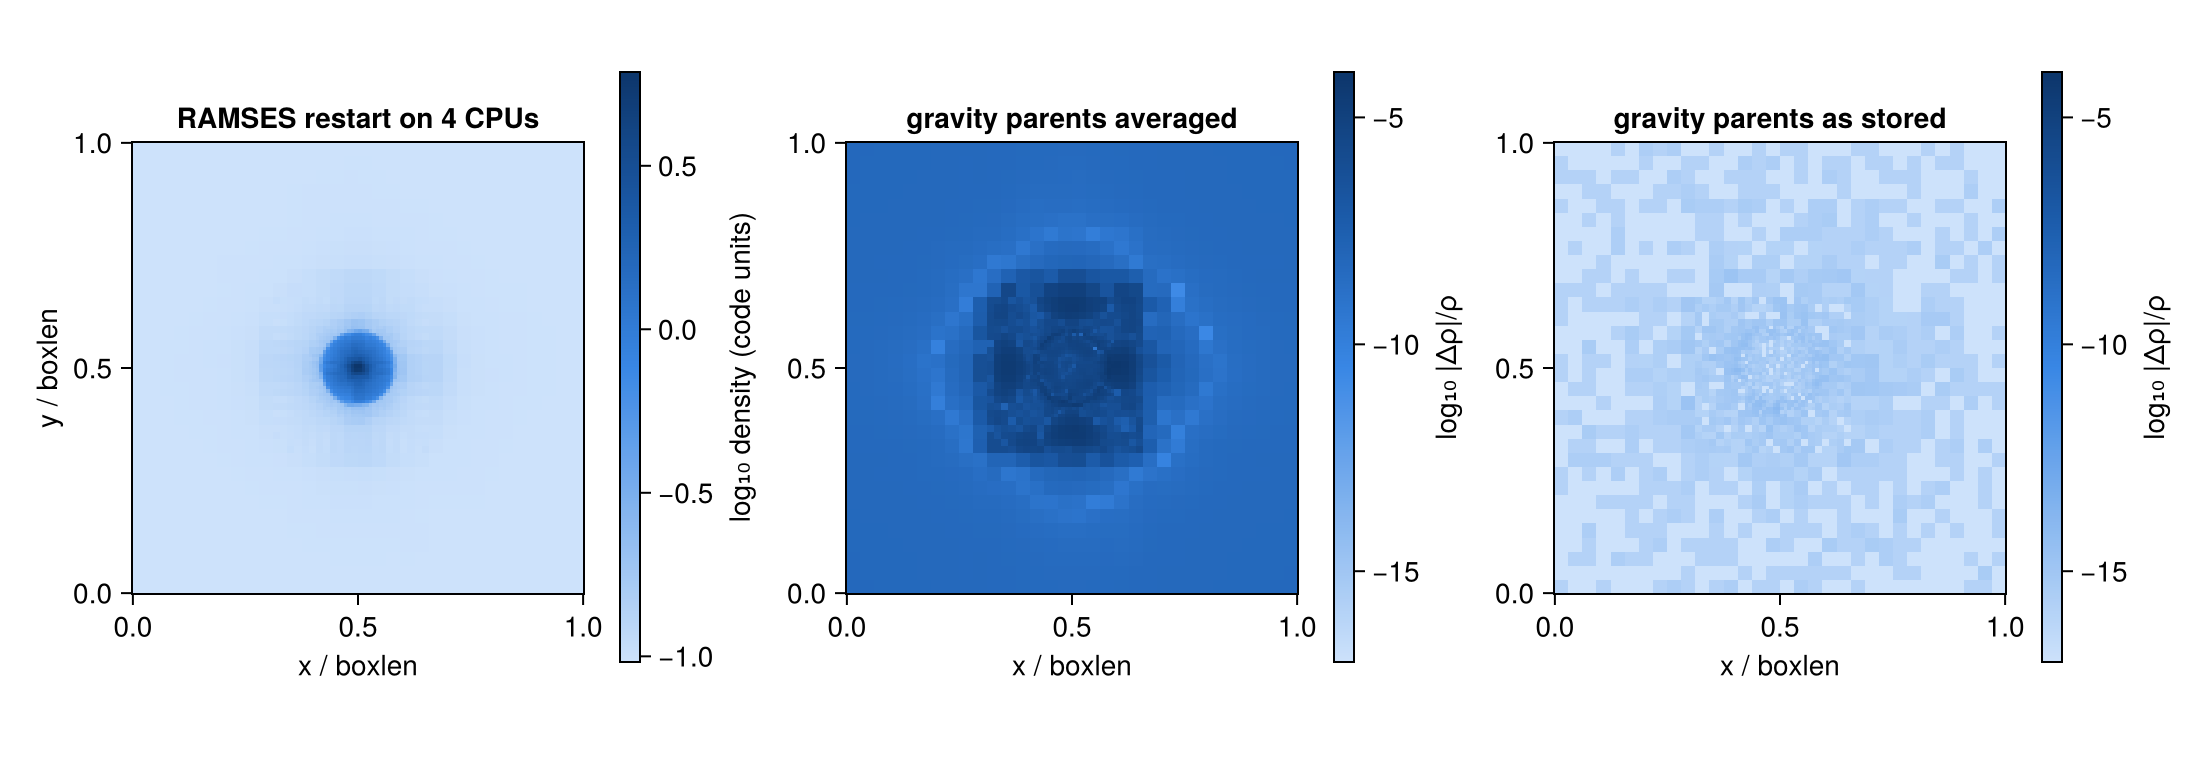

In [25]:
# Where the differences sit: a slice through the centre of the gas, one output after the restart.
ρn = density_slice(joinpath(RUNS, "dm_gas3d_ncpu4_restart", "output_00005"), 5, 0.5, n)
fig = Figure(size=(1100, 390))
ax = Axis(fig[1, 1]; aspect=DataAspect(), title="RAMSES restart on 4 CPUs", xlabel="x / boxlen", ylabel="y / boxlen")
hm = heatmap!(ax, range(0, 1; length=n), range(0, 1; length=n), log10.(ρn); colormap=blues)
Colorbar(fig[1, 2], hm; label="log₁₀ density (code units)", width=10)
for (col, (dir, ttl)) in enumerate(((runa, "gravity parents averaged"), (runm, "gravity parents as stored")))
    rel = abs.(density_slice(joinpath(dir, "output_00005"), 5, 0.5, n) .- ρn) ./ abs.(ρn)
    ax = Axis(fig[1, 2col + 1]; aspect=DataAspect(), title=ttl, xlabel="x / boxlen")
    hm = heatmap!(ax, range(0, 1; length=n), range(0, 1; length=n), log10.(max.(rel, 1e-17));
                  colormap=blues, colorrange=(-17, -4))
    Colorbar(fig[1, 2col + 2], hm; label="log₁₀ |Δρ|/ρ", width=10)
    println(@sprintf("%-26s largest |Δρ|/ρ in this slice: %.1e", ttl, maximum(rel)))
end
fig

Stored gravity parents: round-off. Averaged ones: the gas differs by up to `5e-5` around the
centre, the potential by `3e-6`.

Why the stored values matter: RAMSES computes gravity level by level, and keeps each level's result
in the refined cells. After a restart, its next gravity calculation starts from these values and
stops as soon as the result is accurate enough. Averages of the children are 0.3 to 0.6 % off
RAMSES's own values, so the calculation starts elsewhere, stops at a slightly different answer, and
the gas then moves a little differently. `getgravity(info; parents=true)` keeps RAMSES's values,
they are saved in the mera file, and `writeramses` writes them back.

The hydro parents need no storing. With `interpol_var` 1 or 2, RAMSES averages the children's
**internal** energy and adds the parent's kinetic energy (`upl` in `hydro/interpol_hydro.f90`).
`writeramses` does the same, so the parents match to `1e-16`. Averaging the total energy instead
makes the parent too hot; that cost `2e-4` after a restart of the AMR Sedov run.


With the RAMSES files, use `repartition`, the exact route. `writeramses` is for when only Mera data
is left. Section 11 restarts RAMSES from mera files of every kind of run.


## 9. Mera files written before 1.8.0

Since 1.8.0 a mera file stores the amr header (exact time, time steps per level, step counters), and
the gravity parents when loaded with `parents=true`. For an older file `writeramses` takes the header
from the original simulation if it still exists, with the same result. If the simulation is gone, it
writes anyway and warns: the time steps per level are then unknown, and RAMSES needs them for
gravity and particles. The cost, measured by removing the header, the gravity parents and the
simulation path:


In [26]:
oldruns = [("sedov3d_amr_lb_ncpu4", 6), ("clumps3d_ncpu4", 3), ("sedov3d_grav_part_ncpu4", 6), ("dm_gas3d_ncpu4", 4)]
println(rpad("run", 26), rpad("", 30), rpad("octree", 8), rpad("hydro", 9), rpad("grav", 9), "particles |Δx|")
for (run, o) in oldruns, oldfile in (false, true)
    ri = getinfo(o, joinpath(RUNS, run), verbose=false)
    d  = (hydro     = gethydro(ri; q...),
          gravity   = ri.gravity   ? getgravity(ri; parents=!oldfile, q...) : nothing,
          particles = ri.particles ? getparticles(ri; q...) : nothing)
    if oldfile                                  # as a file saved before 1.8.0, simulation deleted
        for obj in values(d)
            obj === nothing && continue
            obj.info = deepcopy(obj.info)
            empty!(obj.info.grid_info.amr_header); obj.info.path = "/nowhere"
        end
    end
    dir = joinpath(WORK, "oldfile_" * run * (oldfile ? "_old" : "_new"))
    # the old-file case warns (text above); keep the table readable
    w = Base.CoreLogging.with_logger(Base.CoreLogging.NullLogger()) do
        writeramses(3; d..., outpath=dir, verbose=false)
    end
    nmlf = only(filter(endswith(".nml"), readdir(joinpath(RUNS, run))))
    restart_namelist(joinpath(RUNS, run, nmlf), joinpath(dir, nmlf);
                     ngridmax=max(20_000, round(Int, 1.3 * w.ngridmax_needed)),
                     npartmax=isempty(w.npart_per_rank) ? 0 : max(200_000, 3 * w.npart_max))
    run_ramses(dir, nmlf, o, 3) || (println(rpad(run, 26), "RAMSES FAILED"); continue)
    c = compareramses(o + 1, joinpath(RUNS, run * "_restart"), dir; leaves_only=true)
    println(rpad(run, 26), rpad(oldfile ? "old file, simulation gone" : "header and parents", 30),
            rpad(c.same_tree ? "same" : "DIFF", 8), rpad(@sprintf("%.0e", maximum(c.maxdiff["hydro"])), 9),
            rpad(haskey(c.maxdiff, "grav") ? @sprintf("%.0e", maximum(c.maxdiff["grav"])) : "–", 9),
            c.nmatched > 0 ? @sprintf("%.0e", c.particle_maxdiff[1]) : "–")
end

run                                                     octree  hydro    grav     particles |Δx|


sedov3d_amr_lb_ncpu4      header and parents            same    8e-16    –        –


sedov3d_amr_lb_ncpu4      old file, simulation gone     same    8e-16    –        –


clumps3d_ncpu4            header and parents            same    2e-15    8e-15    –


clumps3d_ncpu4            old file, simulation gone     same    2e-16    8e-15    –


sedov3d_grav_part_ncpu4   header and parents            

same    2e-15    1e-12    –


sedov3d_grav_part_ncpu4   old file, simulation gone     same    2e-06    7e-07    –


dm_gas3d_ncpu4            header and parents            same    7e-15    8e-15    6e-16


dm_gas3d_ncpu4            old file, simulation gone     DIFF    3e-02    4e-02    1e-03


Hydro runs are fine without the header. With gravity the differences grow (averaged parents). With
many particles the first step uses a wrong time step, the octree changes and the results differ by
a few per cent. Upgrade such files first.

`upgrade_merafile` adds the header and the gravity parents to an old file while its simulation still
exists. It saves through a temporary file, so an interrupted upgrade cannot damage the original:

```julia
upgrade_merafile(250, "/merafiles")                               # simulation at the recorded path
upgrade_merafile(250, "/merafiles"; simulation="/new/place/sim")  # simulation moved
```


## 10. Other layouts and older RAMSES versions

### Bisection ordering

With `ordering='bisection'` RAMSES cuts the box instead of the curve: a wall splits n ranks into n÷2
and the rest, along x, y and z in turn. The amr files store this tree. `repartition` rebuilds each
rank's files from it (a ghost cell touches the rank's box), builds a new balanced tree for another
rank count, or converts to Hilbert. The restart namelist must name the ordering.

The Sedov run with bisection on 4 ranks from the start:


In [27]:
bis = joinpath(WORK, "sedov_bisection"); mkpath(bis)
nml = replace(read(joinpath(SEDOV, "sedov3d_amr_lb.nml"), String), r"^&RUN_PARAMS\s*$"m => "&RUN_PARAMS\nordering='bisection'")
write(joinpath(bis, "run.nml"), nml)
println("RAMSES from the start, 4 ranks, bisection: ",
        success(pipeline(Cmd(`$MPIRUN -np 4 $RAMSES run.nml`; dir=bis); stdout=joinpath(bis, "run.log"))))
bisref = joinpath(WORK, "sedov_bisection_restart"); mkpath(bisref)      # RAMSES's own restart
cp(joinpath(bis, "output_00006"), joinpath(bisref, "output_00006")); cp(joinpath(bis, "run.nml"), joinpath(bisref, "run.nml"))
println("RAMSES's own restart on 4 ranks: ", run_ramses(bisref, "run.nml", 6, 4))

# RAMSES's own files, rebuilt from their own tree
src = joinpath(bis, "output_00006")
t   = RW.read_global_tree(src, 6; verbose=false)
println("rank 1 rebuilt exactly (own grids, ghosts, tree): ", RW.rank1_reproduced(t, src, 6, 1))

println(rpad("new ranks", 12), rpad("ordering", 12), rpad("octree", 8), "hydro after one output")
for (nr, ord) in ((3, :bisection), (7, :bisection), (3, :hilbert))
    dir = joinpath(WORK, "sedov_bisection_to$(nr)_$ord")
    r = repartition(6, bis, nr; outpath=dir, ordering=ord, verbose=false)
    # the run's own namelist, naming the ordering of the new files
    restart_namelist(joinpath(SEDOV, "sedov3d_amr_lb.nml"), joinpath(dir, "run.nml"); ngridmax=max(20_000, round(Int, 1.3 * r.ngridmax_needed)),
                     run_extra=ord === :bisection ? "ordering='bisection'" : "")
    ok = run_ramses(dir, "run.nml", 6, nr)
    c = compareramses(7, bisref, dir; leaves_only=true)
    println(rpad(nr, 12), rpad(ord, 12), rpad(ok && c.same_tree ? "same" : "DIFF", 8), @sprintf("%.0e", maximum(c.maxdiff["hydro"])))
end

RAMSES from the start, 4 ranks, bisection: true


RAMSES's own restart on 4 ranks: true
rank 1 rebuilt exactly (own grids, ghosts, tree): true
new ranks   ordering    octree  hydro after one output


3           bisection   same    2e-15


7           bisection   same    9e-16


3           hilbert     same    9e-16


Add `ordering='bisection'` to the namelist where the files use it; Hilbert is the default. Mera
also reads bisection outputs (it then reads every file).

### IO groups

With `IOGROUPSIZEREP = n` RAMSES puts the files of every n ranks into one folder `group_GGGGG`.
`repartition` and `writeramses` read such outputs and write them with `iogroupsize = n`:


In [28]:
grp = joinpath(WORK, "sedov_groups")
repartition(6, SEDOV, 5; outpath=grp, iogroupsize=2, verbose=false)
g6 = joinpath(grp, "output_00006")
for d in filter(startswith("group_"), readdir(g6))
    println(d, ": ", join(filter(f -> startswith(f, "amr_"), readdir(joinpath(g6, d))), ", "))
end
c = compareramses(6, SEDOV, grp)
println("every value kept: ", c.same_tree && all(v -> all(iszero, v), values(c.maxdiff)))

group_00001: amr_00006.out00001, amr_00006.out00002
group_00002: amr_00006.out00003, amr_00006.out00004
group_00003: amr_00006.out00005
every value kept: true

In the RAMSES version used here `IOGROUPSIZEREP` is fixed at compile time (`amr/amr_parameters.f90`),
so a grouped output restarts only with a build of the same value. Two quirks of that version:

- it looks for `output_N/info_N.txt` even with groups, so the writer puts a copy there;
- it creates only the `group_00001` folder of its next output, so the other group folders must exist
  before it writes.

With a build for `IOGROUPSIZEREP = 2`, grouped outputs from both writers restarted on 3 ranks to
round-off (hydro `8e-16` for the AMR Sedov run; hydro `7e-15`, gravity `8e-15`, particles `5e-16`
box lengths for the run with gravity and particles).

### Older RAMSES versions

Outputs from before 2018 differ, and each difference is handled:

| what | how it is handled |
|---|---|
| no `namelist.txt` | walls read from the boundary grids in the amr files; wall type and ghost width chosen so that rank 1's file is rebuilt exactly (if none fits, the namelist is asked for); `interpol_var` from the stored parent cells |
| no hydro descriptor | the variable layout Mera detects (MHD: face fields at 5 to 10, pressure at 11) |
| particle files without `part_file_descriptor.txt` | read and written in their legacy layout, metallicity included |
| gravity files with the forces only | read as `[:ax, :ay, :az]` |

A cosmological run from such a version, the yt sample output `output_00080` (16 ranks, 1.09 million
particles), loaded with Mera and
written back:


In [29]:
COSMO = get(ENV, "MERA_COSMO", "/Volumes/FASTStorage/Simulations/Mera-Tests/RAMSES/yt_cosmo")
ci = getinfo(80, COSMO, verbose=false)
println("gravity variables: ", ci.gravity_variable_list, ";  particle fields: ", ci.particles_variable_list)
cgas = gethydro(ci; q...); cgrav = getgravity(ci; parents=true, q...); cpart = getparticles(ci; q...)
println("complete: ", first(restart_completeness(cgas; gravity=cgrav, particles=cpart)))
cw = joinpath(WORK, "cosmo_from_mera")
writeramses(8; hydro=cgas, gravity=cgrav, particles=cpart, outpath=cw, verbose=false)
c = compareramses(80, COSMO, cw)
println(@sprintf("octree %s; all cells, largest difference: hydro %.0e, gravity %.0e; particles %d of %d, position %.0e",
                 c.same_tree ? "same" : "DIFF", maximum(c.maxdiff["hydro"]), maximum(c.maxdiff["grav"]),
                 c.nparticles[2], c.nparticles[1], c.particle_maxdiff[1]))
cgas = cgrav = cpart = nothing; GC.gc()

gravity variables: 

[:ax, :ay, :az];  particle fields: [:vx, :vy, :vz, :mass, :birth, :metals]


complete: true

octree same; all cells, largest difference: hydro 6e-17, gravity 0e+00; particles 1090895 of 1090895, position 0e+00


Every cell and every particle equals the original. Legacy stars are numbered apart from dark
matter, so `compareramses` matches them by identity and kind.


## 11. Every kind of run, every route

Two tests on every kind of data: first the written files, then RAMSES restarting from mera files.

### The files

Each public test simulation goes through six routes: `repartition` to Hilbert on 3 ranks, to
bisection on 5 ranks and to IO groups, and the same three with `writeramses` from a mera file.
RAMSES does not run here; the files are compared with the original.

To run this section yourself, download the test simulations first. `download_testdata()`
returns a folder that the code below finds through `MERA_TEST_DATA`:

```julia
ENV["MERA_TEST_DATA"] = download_testdata()   # all 15 test simulations, 307 MB
```

How to read the table:

- **repartition**, **mera file: leaves**: the largest difference over every variable, particle and
  sink, relative to the variable's largest value. Zero is a bit-for-bit copy.
- **refined cells, local**: rebuilt cells carry round-off. Each is compared with the size of what was
  averaged into it (the cell and its 8 children), so an error would show even in a faint cell. For
  the pressure that size includes (γ − 1) times the kinetic and magnetic energy density, because
  the pressure is the total energy minus those two.
- **–**: RAMSES keeps no averages here. On a uniform grid it never updates the cells below
  `levelmin`; with `static_gas=.true.` (`clumps3d`) the gas never evolves. The restarts below show
  that these runs continue to round-off.

IO-group outputs are first converted to plain files for Mera's readers. The test suite
(`test/86_ramses_writer_tests.jl`) runs the same matrix and also rebuilds every rank's files.


In [30]:
PUBLIC = joinpath(get(ENV, "MERA_TEST_DATA", "/Volumes/FASTStorage/Simulations/Mera-Tests"), "RAMSES-PUBLIC")
sims = [("sedov3d_amr", 7, "AMR hydro, periodic"), ("sedov3d_grav_part", 7, "gravity, tracer particles"),
        ("mhdtube3d", 6, "MHD, outflow walls"), ("clumps3d", 4, "clumps, gravity"),
        ("stromgren3d", 7, "RT, uniform grid, walls"), ("sinks3d", 2, "sinks, gravity, particles"),
        ("ramses_abc_flow", 2, "MHD, uniform grid"), ("ramses_rt_dirac", 2, "RT and MHD, AMR"),
        ("legacy_particles3d", 3, "legacy particles, one rank"), ("cosmo3d", 3, "cosmological, gas and DM"),
        ("sedov3d_bisection", 6, "RAMSES bisection output"), ("dm_gas3d_bisection", 4, "bisection, gravity, DM"),
        ("sedov3d_iogroups", 3, "RAMSES IO-group output")]
routes = [("Hilbert", 3, (ordering=:hilbert,)), ("bisection", 5, (ordering=:bisection,)),
          ("IO groups", 3, (ordering=:hilbert, iogroupsize=2))]
worst(c) = c.same_tree ? maximum(vcat([maximum(v) for v in values(c.maxdiff)], collect(c.particle_maxdiff), c.sink_maxdiff)) : Inf
# The refined cells only, each compared with the size of what was averaged into it: the cell and its
# 8 children, and for the pressure also (gamma - 1) times their kinetic and magnetic energy density.
function local_scale(vals, v, names, gamma)
    s = maximum(abs, vals[v])
    if names[v] === :p
        iv = [findfirst(==(c), names) for c in (:vx, :vy, :vz)]
        ib = [findfirst(==(c), names) for c in (:bx_left, :by_left, :bz_left, :bx_right, :by_right, :bz_right)]
        for k in eachindex(vals[1])
            e = 0.5 * vals[1][k] * sum(vals[i][k]^2 for i in iv)
            all(!isnothing, ib) && (e += 0.125 * sum((vals[ib[d]][k] + vals[ib[d+3]][k])^2 for d in 1:3))
            s = max(s, (gamma - 1) * e)
        end
    end
    s
end
function refined_local(src, out, iout, info)
    ta, tb = RW.read_global_tree(src, iout; verbose=false), RW.read_global_tree(out, iout; verbose=false)
    worst = 0.0
    for (kind, names) in (("hydro", info.variable_list), ("grav", info.gravity_variable_list), ("rt", info.rt_variable_list))
        ca = RW.open_cell_files(src, kind, iout, ta.header.ncpu, ta.header.nlevelmax, length(ta.boundaries))
        ca === nothing && continue
        cb = RW.open_cell_files(out, kind, iout, tb.header.ncpu, tb.header.nlevelmax, length(tb.boundaries))
        for l in 1:RW.nlevels(ta)-1, (g, ig) in enumerate(ta.levels[l].ig), ind in 1:8
            gc = RW.find_grid(ta, l + 1, RW.child_coord(ig, ind)); gc == 0 && continue
            h = tb.levels[l].lookup[ig]
            vals = [vcat(RW.cell_value(ca, ta.src_cpu[l][g], l, ta.src_cpu[l][g], ta.src_pos[l][g], ind, v),
                         [RW.cell_value(ca, ta.src_cpu[l+1][gc], l + 1, ta.src_cpu[l+1][gc], ta.src_pos[l+1][gc], k, v) for k in 1:8])
                    for v in 1:ca.nvar]
            for v in 1:ca.nvar
                b = RW.cell_value(cb, tb.src_cpu[l][h], l, tb.src_cpu[l][h], tb.src_pos[l][h], ind, v)
                worst = max(worst, abs(vals[v][1] - b) / max(local_scale(vals, v, names, info.gamma), floatmin()))
            end
        end
    end
    worst
end
static(info) = lowercase(strip(string(get(get(info.namelist_content, "&RUN_PARAMS", Dict()), "static_gas", ".false.")))) in (".true.", "t", ".t.")
M = fill(NaN, length(sims), 7)       # repartition x3 | mera-file leaves (all routes) | mera-file refined x3
for (i, (name, o, _)) in enumerate(sims)
    src = joinpath(PUBLIC, name); dir = joinpath(src, "output_" * lpad(o, 5, '0'))
    for (j, (lab, n, kw)) in enumerate(routes)                       # RAMSES files to RAMSES files
        out = joinpath(WORK, "matrix", name, "repartition " * lab)
        repartition(o, src, n; outpath=out, overwrite=true, verbose=false, kw...)
        M[i, j] = worst(compareramses(o, src, out))
    end
    mpath = src                                                       # Mera's readers need plain files
    if RW.groupsize_of(dir) > 0
        mpath = joinpath(WORK, "matrix", name, "plain"); RW.repartition(dir, 4; outpath=mpath, overwrite=true, verbose=false)
    end
    mi = getinfo(o, mpath, verbose=false); uniform = mi.levelmin == mi.levelmax
    d = (hydro = gethydro(mi; q...), gravity = mi.gravity ? getgravity(mi; parents=true, q...) : nothing,
         rt = mi.rt ? getrt(mi; q...) : nothing, particles = mi.particles ? getparticles(mi; q...) : nothing,
         sinks = mi.sinks ? getsinks(mi; verbose=false) : nothing)
    mf = mkpath(joinpath(WORK, "matrix", name, "merafile")); mode = :write
    for obj in values(d)
        obj === nothing && continue
        savedata(obj, mf, mode; verbose=false); mode = :append
    end
    L = NamedTuple{keys(d)}(Tuple(obj === nothing ? nothing : loaddata(o, mf, k; verbose=false) for (k, obj) in pairs(d)))
    M[i, 4] = 0.0
    for (j, (lab, n, kw)) in enumerate(routes)                       # mera file to RAMSES files
        out = joinpath(WORK, "matrix", name, "mera file " * lab)
        Base.CoreLogging.with_logger(Base.CoreLogging.NullLogger()) do
            writeramses(n; L..., outpath=out, overwrite=true, verbose=false, kw...)
        end
        M[i, 4] = max(M[i, 4], worst(compareramses(o, src, out; leaves_only=true)))
        # RAMSES keeps no averages to compare with on a uniform grid or with static gas
        M[i, 4 + j] = uniform || static(mi) ? NaN : refined_local(dir, joinpath(out, "output_" * lpad(o, 5, '0')), o, mi)
    end
end
cols = ["repartition: " .* first.(routes); "mera file: leaves, all routes"; "mera file, refined: " .* first.(routes)]
cell(x) = rpad(isnan(x) ? "–" : x == 0 ? "0" : @sprintf("%.0e", x), 11)
println(rpad("", 50), rpad("RAMSES files to RAMSES files", 33), "| mera file: leaves | refined cells, local")
println(rpad("simulation", 22), rpad("covers", 28), join(rpad(r[1], 11) for r in routes), "| ", rpad("all", 9), "| ",
        join(rpad(r[1], 11) for r in routes))
for (i, (name, _, what)) in enumerate(sims)
    println(rpad(name, 22), rpad(what, 28), join(cell(x) for x in M[i, 1:3]), "| ", rpad(cell(M[i, 4]), 9), "| ",
            join(cell(x) for x in M[i, 5:7]))
end

                                                  RAMSES files to RAMSES files     

| mera file: leaves | refined cells, local
simulation            covers                      Hilbert    bisection  IO groups  | all      | Hilbert    bisection  IO groups  
sedov3d_amr           AMR hydro, periodic         0          0          0          | 0          | 7e-16      7e-16      7e-16      
sedov3d_grav_part     gravity, tracer particles   0          0          0          | 0          | 7e-16      7e-16      7e-16      
mhdtube3d             MHD, outflow walls          0          0          0          | 0          | 6e-16      6e-16      6e-16      
clumps3d              clumps, gravity             0          0          0          | 0          | –          –          –          
stromgren3d           RT, uniform grid, walls     0          0          0          | 0          | –          –          –          
sinks3d               sinks, gravity, particles   0          0          0          | 0          | 8e-16      8e-16      8e-16      
ramses_abc_flow       MHD, uniform 

### RAMSES restarts from a mera file

Every kind of run: saved as a mera file, written in both orderings, restarted by RAMSES, compared
with RAMSES's own restart (leaf cells, one output later). The gravity is loaded with `parents=true`:


In [31]:
RAMSES_MHD = get(ENV, "MERA_RAMSES_MHD_BIN", "/Volumes/FASTStorage/projects/RamsesConverter/build/mhd/bin/ramses3d_mhd")
RAMSES_RT  = get(ENV, "MERA_RAMSES_RT_BIN",  "/Volumes/FASTStorage/projects/RamsesConverter/build/rt/bin/ramses3d_rt")
# (run, restart output, RAMSES's own restart, build, what it covers)
mruns = [("sedov3d_amr_lb_ncpu4", 6, "sedov3d_amr_lb_ncpu4_restart", RAMSES, "AMR hydro"),
         ("sedov3d_uniform_ncpu4", 5, "sedov3d_uniform_ncpu4_restart", RAMSES, "uniform grid"),
         ("sedov3d_outflow_ncpu4", 4, "sedov3d_outflow_ncpu4_restart", RAMSES, "outflow walls"),
         ("sedov3d_grav_part_ncpu4", 6, "sedov3d_grav_part_ncpu4_restart", RAMSES, "gravity, tracer particles"),
         ("dm_gas3d_ncpu4", 4, "dm_gas3d_ncpu4_restart", RAMSES, "gravity, dark matter"),
         ("sinks3d_ncpu4", 4, "sinks3d_ncpu4_restart", RAMSES, "sinks, gravity, particles"),
         ("clumps3d_ncpu4", 3, "clumps3d_ncpu4_restart", RAMSES, "clumps, gravity"),
         ("mhdtube3d_ncpu4", 5, "mhdtube3d_ncpu4_restart", RAMSES_MHD, "MHD, outflow walls"),
         ("stromgren3d_ncpu4", 6, "stromgren3d_ncpu4_restart", RAMSES_RT, "radiative transfer, walls"),
         ("cosmo3d_ncpu8", 3, "cosmo3d_ncpu8_restart2", RAMSES, "cosmological: gas, DM, gravity"),
         ("starform3d_ncpu4", 4, "starform3d_ncpu4_restart", RAMSES, "stochastic star formation")]
restarts = NamedTuple[]
println(rpad("run", 24), rpad("covers", 32), rpad("ordering", 11), rpad("ranks", 6), rpad("octree", 8), rpad("hydro", 8), rpad("grav", 8), rpad("rt", 8), "particles")
for (run, o, ref, bin, what) in mruns
    src = joinpath(RUNS, run); ri = getinfo(o, src, verbose=false)
    d = (hydro     = gethydro(ri; q...),
         gravity   = ri.gravity   ? getgravity(ri; parents=true, q...) : nothing,
         rt        = ri.rt        ? getrt(ri; q...) : nothing,
         particles = ri.particles ? getparticles(ri; q...) : nothing,
         sinks     = ri.sinks     ? getsinks(ri; verbose=false) : nothing)
    mf = mkpath(joinpath(WORK, "merafile_" * run)); mode = :write          # through a mera file
    for obj in values(d)
        obj === nothing && continue
        savedata(obj, mf, mode; verbose=false); mode = :append
    end
    L = NamedTuple{keys(d)}(Tuple(obj === nothing ? nothing : loaddata(o, mf, k; verbose=false) for (k, obj) in pairs(d)))
    nmlf = only(filter(endswith(".nml"), readdir(joinpath(RUNS, ref))))
    # the cosmological reference stops two coarse steps after the restart and writes after each
    steps = occursin("cosmo", run) ? "nstepmax=$(ri.grid_info.nstep_coarse + 2)" : ""
    for (ord, n) in (("hilbert", 3), ("bisection", 5))
        dir = joinpath(WORK, "mera_restart_$(run)_$ord")
        w = Base.CoreLogging.with_logger(Base.CoreLogging.NullLogger()) do
            writeramses(n; L..., outpath=dir, ordering=Symbol(ord), overwrite=true, verbose=false)
        end
        restart_namelist(joinpath(RUNS, ref, nmlf), joinpath(dir, nmlf);
                         ngridmax=max(20_000, round(Int, 1.3 * w.ngridmax_needed)),
                         npartmax=isempty(w.npart_per_rank) ? 0 : max(200_000, 3 * w.npart_max),
                         run_extra=join(filter(!isempty, [ord == "bisection" ? "ordering='bisection'" : "", steps]), "\n"),
                         output_extra=isempty(steps) ? "" : "foutput=1")
        isdir(joinpath(src, "ic")) && !ispath(joinpath(dir, "ic")) && symlink(realpath(joinpath(src, "ic")), joinpath(dir, "ic"))
        run_ramses(dir, nmlf, o, n; bin=bin) || (println(rpad(run, 24), "RAMSES FAILED"); continue)
        c = compareramses(o + 1, joinpath(RUNS, ref), dir; leaves_only=true)
        f(k) = haskey(c.maxdiff, k) ? maximum(c.maxdiff[k]) : NaN
        push!(restarts, (run=run, what=what, ordering=ord, ranks=n, same=c.same_tree, hydro=f("hydro"), grav=f("grav"),
                         rt=f("rt"), part=c.nmatched > 0 ? c.particle_maxdiff[1] : NaN))
        r = restarts[end]; s(x) = isnan(x) ? "–" : @sprintf("%.0e", x)
        println(rpad(run, 24), rpad(what, 32), rpad(ord, 11), rpad(n, 6), rpad(r.same ? "same" : "DIFF", 8),
                rpad(s(r.hydro), 8), rpad(s(r.grav), 8), rpad(s(r.rt), 8), s(r.part))
    end
end

run                     covers                          

ordering   ranks octree  hydro   grav    rt      particles


sedov3d_amr_lb_ncpu4    AMR hydro                       hilbert    3     same    8e-16   –       –       –


sedov3d_amr_lb_ncpu4    AMR hydro                       bisection  5     same    1e-15   –       –       –


sedov3d_uniform_ncpu4   uniform grid                    hilbert    3     same    5e-16   –       –       –


...

hilbert    3     same    8e-16   6e-12   –       1e-16


cosmo3d_ncpu8           cosmological: gas, DM, gravity  bisection  5     same    4e-16   1e-14   –       1e-16


starform3d_ncpu4        stochastic star formation       

hilbert    3     same    5e-02   8e-03   –       1e-01


starform3d_ncpu4        stochastic star formation       bisection  5     same    4e-02   8e-03   –       1e-01


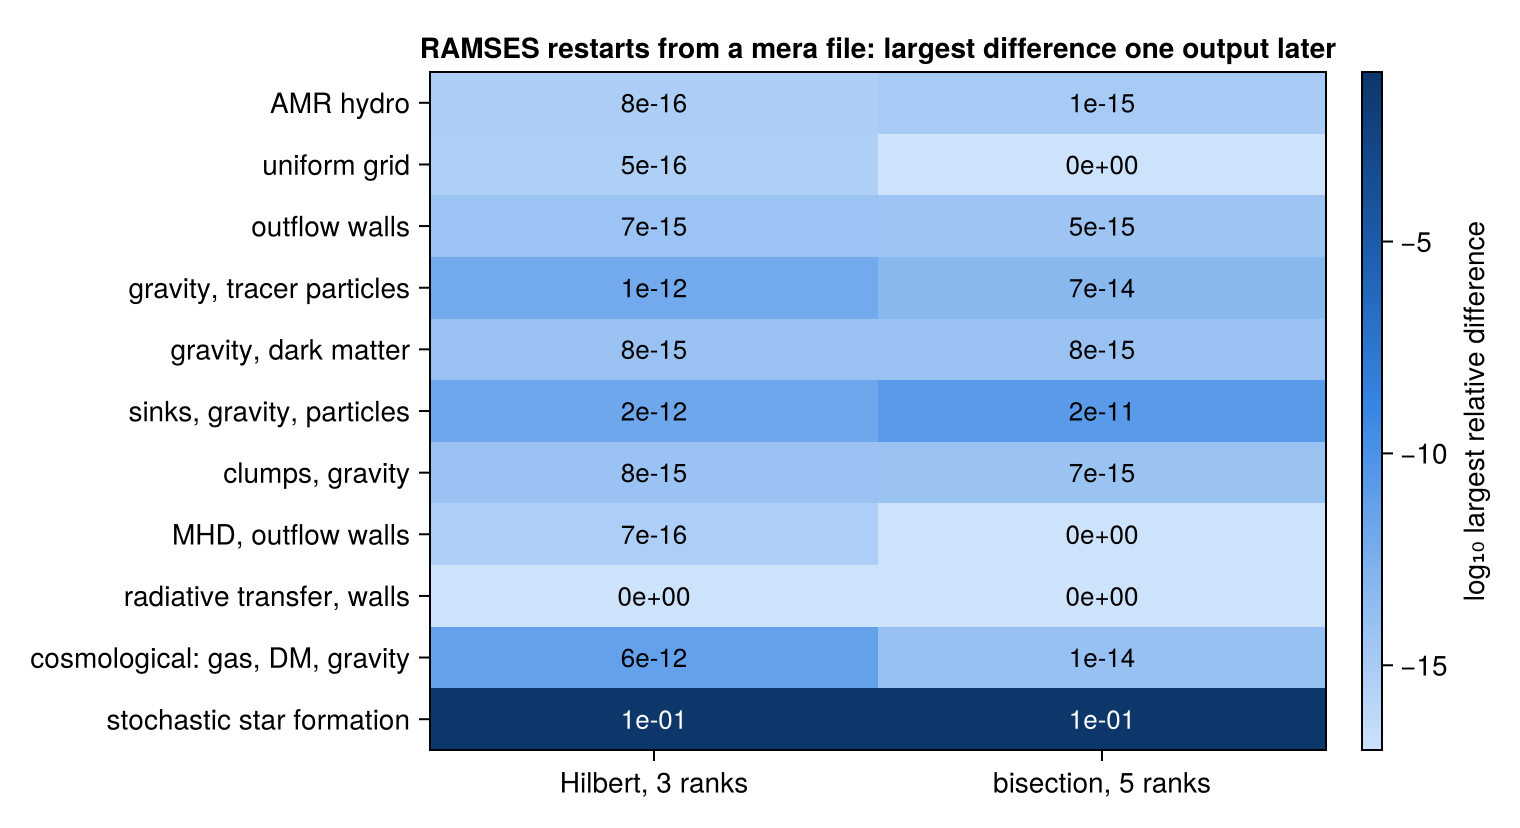

In [32]:
# The same table as a picture: the largest difference of each restart (hydro, gravity, RT and
# particle positions together), on the scale from round-off to the stochastic run.
labs = unique([(r.run, r.what) for r in restarts])
pick(run, ord) = only(r for r in restarts if r.run == run && r.ordering == ord)
V = [maximum(filter(!isnan, [r.hydro, r.grav, r.rt, r.part])) for r in (pick(run, ord) for (run, _) in labs, ord in ("hilbert", "bisection"))]
fig = Figure(size=(760, 40 + 34 * length(labs)))
ax = Axis(fig[1, 1]; xticks=(1:2, ["Hilbert, 3 ranks", "bisection, 5 ranks"]), yticks=(1:length(labs), [w for (_, w) in labs]),
          yreversed=true, title="RAMSES restarts from a mera file: largest difference one output later")
hm = heatmap!(ax, 1:2, 1:length(labs), permutedims(log10.(max.(V, 1e-17))); colormap=blues, colorrange=(-17, -1))
for i in eachindex(labs), j in 1:2
    text!(ax, j, i; text=@sprintf("%.0e", V[i, j]), align=(:center, :center), fontsize=13,
          color=V[i, j] > 1e-6 ? :white : :black)
end
Colorbar(fig[1, 2], hm; label="log₁₀ largest relative difference", width=10)
fig

| run type | difference after one output | why |
|---|---|---|
| hydro on AMR or uniform grids, with physical walls | round-off | the rebuilt parents are RAMSES's own |
| with self-gravity, particles, sinks or clumps | round-off (gravity `1e-11` or better) | the gravity parents are kept as stored (`parents=true`) |
| MHD and radiative transfer | round-off | the two rules below |
| cosmological (gas, dark matter, gravity, AMR) | round-off | the exact amr header carries the expansion factor and its time steps |
| stochastic star formation | statistical | random seeds depend on the rank count |

Hilbert and bisection give the same result; the ordering only decides which rank holds which cell.
The two rules: an MHD parent takes each face field from the four children on that face; photon
densities are zero below `levelmin`, because RAMSES sets the light speed to zero there, and their
fluxes are averaged like every other parent.


### Where an error would show

A converter's most likely bug is a wrong ghost cell or pointer at a border between ranks, so it
would show along those borders. Three hard cases, each the full chain: the RAMSES output was saved
as a mera file, `writeramses` wrote it for a new number of ranks, and RAMSES restarted from that.
The maps show |Δρ|/ρ between this restart and RAMSES's own restart on the original ranks, one output
later, in a slice. Black dots: the borders between the new ranks.


cosmological: 8 → 5 ranks (bisection)      largest |Δρ|/ρ in the slice 4.2e-16


MHD tube: 4 → 3 ranks (Hilbert)            largest |Δρ|/ρ in the slice 0.0e+00


radiative transfer: 4 → 5 ranks (bisection) largest |Δρ|/ρ in the slice 0.0e+00


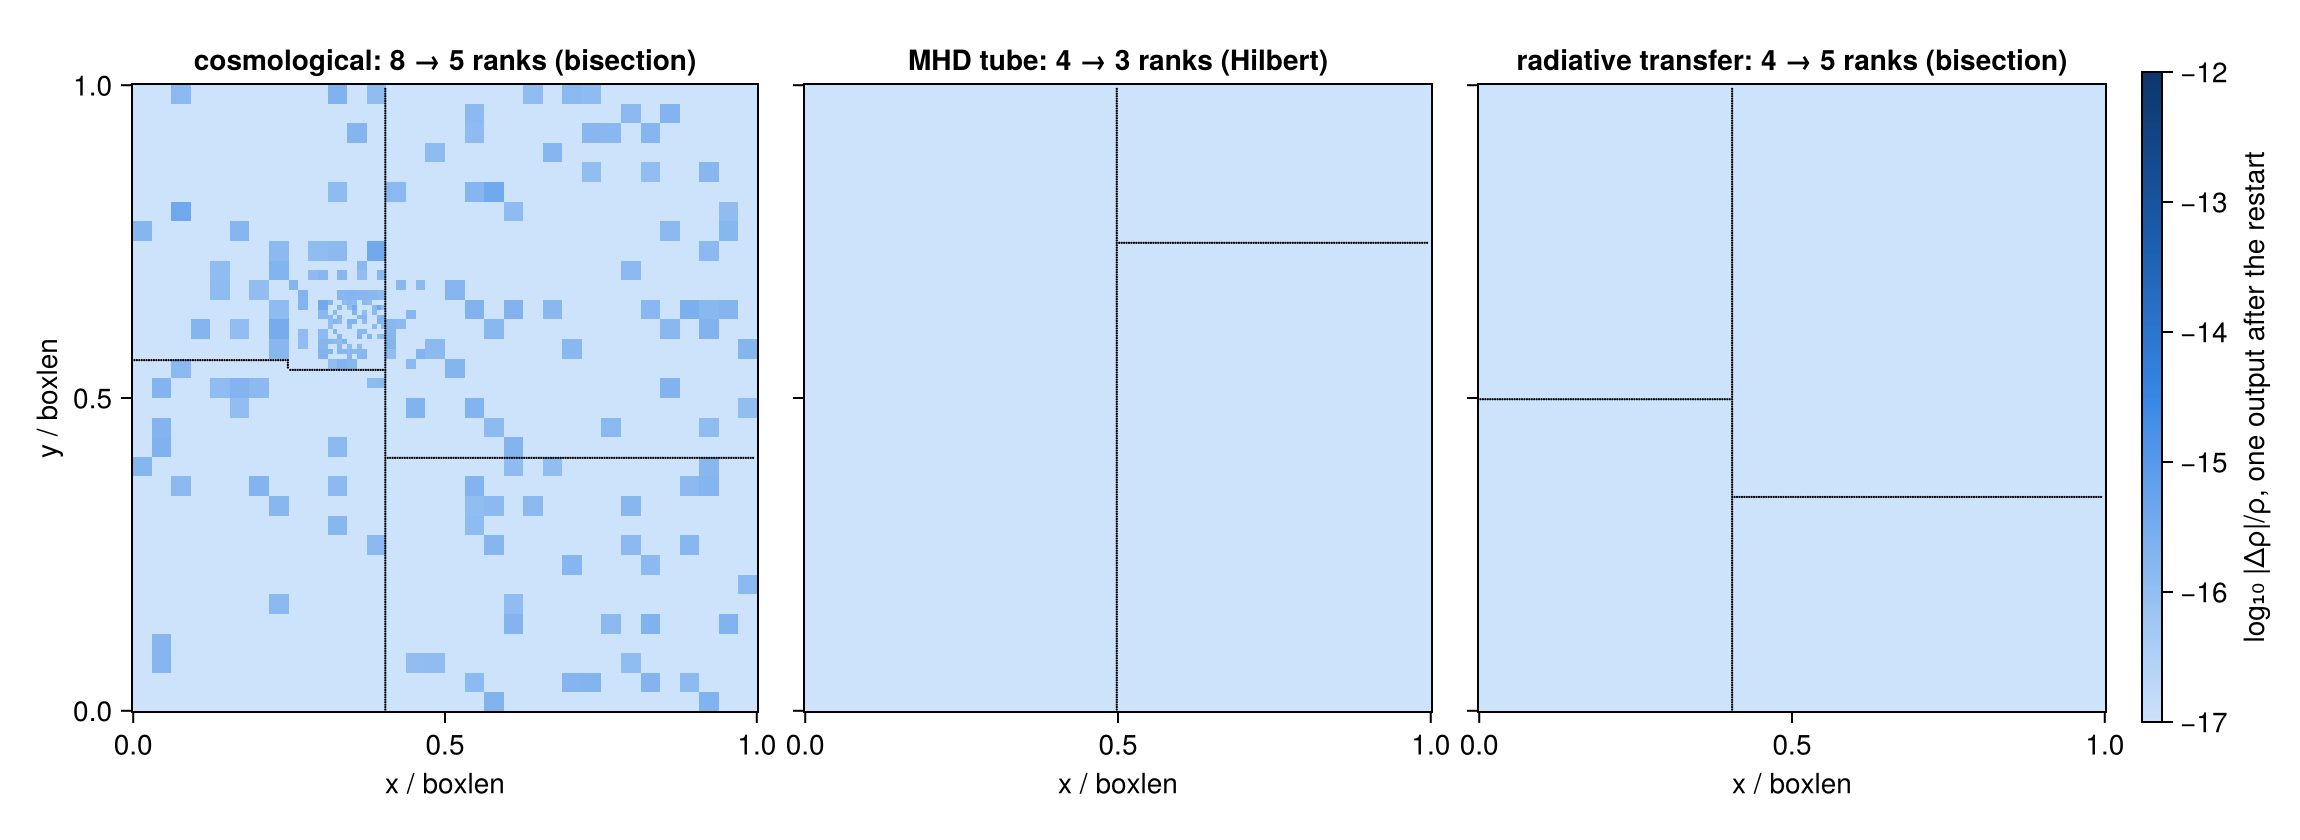

In [33]:
# The leaf cell under each pixel for any box, also with wall layers (coarse cells around the box).
function leaf_slice(t, z, n, value)
    g0 = t.geom; img = fill(NaN, n, n)
    for i in 1:n, j in 1:n
        xc = ntuple(d -> g0.cmin[d] + (d == 1 ? (i - 0.5) / n : d == 2 ? (j - 0.5) / n : z) * g0.nx_loc, 3)
        g = RW.find_grid(t, 1, RW.Coord(ntuple(d -> floor(Int32, xc[d]), 3))); g == 0 && continue
        l = 1
        while true
            c = ntuple(d -> floor(Int, xc[d] * 2^l), 3)
            child = RW.find_grid(t, l + 1, RW.Coord(c))
            child == 0 && (img[i, j] = value(l, g, RW.cell_index((c .& 1)...)); break)
            g, l = child, l + 1
        end
    end
    img
end
function reldiff_slice(ref, new, iout, z, n; kind="hydro", ivar=1)
    ta, tb = RW.read_global_tree(ref, iout; verbose=false), RW.read_global_tree(new, iout; verbose=false)
    ca = RW.open_cell_files(ref, kind, iout, ta.header.ncpu, ta.header.nlevelmax, length(ta.boundaries))
    cb = RW.open_cell_files(new, kind, iout, tb.header.ncpu, tb.header.nlevelmax, length(tb.boundaries))
    leaf_slice(ta, z, n, (l, g, ind) -> begin
        h = tb.levels[l].lookup[ta.levels[l].ig[g]]
        a = RW.cell_value(ca, ta.src_cpu[l][g], l, ta.src_cpu[l][g], ta.src_pos[l][g], ind, ivar)
        b = RW.cell_value(cb, tb.src_cpu[l][h], l, tb.src_cpu[l][h], tb.src_pos[l][h], ind, ivar)
        abs(a - b) / max(abs(a), floatmin())
    end)
end
# pixels where the rank changes: the borders of the domains RAMSES restarted from
function rank_borders(dir, iout, z, n)
    t = RW.read_global_tree(dir, iout; verbose=false); dec = RW.own_decomposition(t)
    r = leaf_slice(t, z, n, (l, g, ind) -> Float64(dec.cpu_map[l][g, ind]))
    [Point2f((i - 0.5) / n, (j - 0.5) / n) for i in 1:n-1, j in 1:n-1 if r[i, j] != r[i+1, j] || r[i, j] != r[i, j+1]]
end
cases = [("cosmo3d_ncpu8", "bisection", 3, 0.5, "cosmological: 8 → 5 ranks (bisection)"),
         ("mhdtube3d_ncpu4", "hilbert", 5, 0.5, "MHD tube: 4 → 3 ranks (Hilbert)"),
         ("stromgren3d_ncpu4", "bisection", 6, 0.03, "radiative transfer: 4 → 5 ranks (bisection)")]
refs = Dict(r[1] => r[3] for r in mruns)
fig = Figure(size=(1150, 420))
for (col, (run, ord, o, zs, ttl)) in enumerate(cases)
    dir = joinpath(WORK, "mera_restart_$(run)_$ord")
    d = reldiff_slice(joinpath(RUNS, refs[run], "output_" * lpad(o + 1, 5, '0')), joinpath(dir, "output_" * lpad(o + 1, 5, '0')), o + 1, zs, n)
    ax = Axis(fig[1, col]; aspect=DataAspect(), title=ttl, xlabel="x / boxlen", ylabel=col == 1 ? "y / boxlen" : "",
              yticklabelsvisible=col == 1)
    hm = heatmap!(ax, range(0, 1; length=n), range(0, 1; length=n), log10.(max.(d, 1e-17)); colormap=blues, colorrange=(-17, -12))
    scatter!(ax, rank_borders(joinpath(dir, "output_" * lpad(o, 5, '0')), o, zs, n); color=:black, markersize=1.6)
    col == 3 && Colorbar(fig[1, 4], hm; label="log₁₀ |Δρ|/ρ, one output after the restart", width=10)
    @printf("%-42s largest |Δρ|/ρ in the slice %.1e\n", ttl, maximum(filter(!isnan, d)))
end
fig

Round-off without structure, or exactly zero, and nothing along the rank borders: the new files
give RAMSES the same neighbours at every border as its own files.


## 12. When results differ, and by how much

Every route copies values or computes them as RAMSES does, so differences come from few places:

| where | largest difference | why |
|---|---|---|
| `repartition`: every cell, particle and sink | 0 | copied (§5, §11) |
| `writeramses`: leaf cells, particles, sinks | 0 | copied (§8, §11) |
| `writeramses`: refined hydro, MHD and RT cells | `1e-15` of the averaged values | RAMSES's rules; only the order of the additions differs (§11) |
| RAMSES continuing from converted files | `1e-15` (hydro) to `2e-11` (gravity) | sums are added in another order on another rank count; the gravity solver then stops at a slightly different answer within its tolerance (§7, §11) |
| stochastic star formation, Monte-Carlo tracers | statistical | random seeds depend on the rank count (§7) |

Two avoidable cases give more:

| case | difference | how to avoid it |
|---|---|---|
| gravity loaded without `parents=true` | gas `5e-5`, potential `3e-6` | `getgravity(info; parents=true)` (§8) |
| mera file from before 1.8.0 whose simulation is gone | up to a few per cent with many particles | `upgrade_merafile` while the simulation still exists (§9) |

**Is that small enough?** The yardstick is RAMSES itself. Every restart changes a run a little,
even when RAMSES restarts from its own files on its own ranks, and nobody counts that as an error.
So a difference counts as small enough when it is no larger than that, or when the reason it is
larger is known and lies inside RAMSES (below).

The table measures both over the same interval, one output after the restart, as the largest
relative difference to a reference: "from a mera file" is the route of this page, on any rank count
(section 11); "RAMSES restarting itself" is RAMSES's own restart on its original ranks against the
same run computed straight through, without a restart:


In [34]:
# What RAMSES gives by itself: its own restart on the original ranks against the run that never
# stopped, one output after the restart (leaf cells, every variable, particle positions). The
# cosmological reference of section 11 stops after one coarse step, so here its other restart is
# used, which runs to the next output at a = 0.2: a longer interval.
alone = Dict{String,Float64}()
for (run, o, ref, _, _) in mruns
    ref1 = occursin("cosmo", run) ? "cosmo3d_ncpu8_restart" : ref
    c = compareramses(o + 1, joinpath(RUNS, run), joinpath(RUNS, ref1); leaves_only=true)
    v = [maximum(x) for x in values(c.maxdiff)]
    c.nmatched > 0 && push!(v, c.particle_maxdiff[1])
    alone[run] = maximum(v)
end
println(rpad("run", 24), rpad("covers", 32), rpad("from a mera file", 18), "RAMSES restarting itself")
for (run, _, _, _, what) in mruns
    m = maximum(maximum(filter(!isnan, [r.hydro, r.grav, r.rt, r.part])) for r in restarts if r.run == run)
    println(rpad(run, 24), rpad(what, 32), rpad(@sprintf("%.0e", m), 18), @sprintf("%.0e", alone[run]),
            occursin("cosmo", run) ? "   (to a = 0.2)" : "")
end

run                     covers                          from a mera file  RAMSES restarting itself
sedov3d_amr_lb_ncpu4    AMR hydro                       1e-15             1e-15
sedov3d_uniform_ncpu4   uniform grid                    5e-16             9e-16
sedov3d_outflow_ncpu4   outflow walls                   7e-15             7e-15
sedov3d_grav_part_ncpu4 gravity, tracer particles       1e-12             6e-14
dm_gas3d_ncpu4          gravity, dark matter            8e-15             8e-15
sinks3d_ncpu4           sinks, gravity, particles       2e-11             2e-15
clumps3d_ncpu4          clumps, gravity                 8e-15             0e+00
mhdtube3d_ncpu4         MHD, outflow walls              7e-16             3e-15
stromgren3d_ncpu4       radiative transfer, walls       0e+00             1e-15
cosmo3d_ncpu8           cosmological: gas, DM, gravity  6e-12             9e-14   (to a = 0.2)
starform3d_ncpu4        stochastic star formation       1e-01             6e-15


**Hydro, MHD and RT:** about `1e-15`, as close as RAMSES gets to itself.

**Gravity:** up to `2e-11` after a change of rank count, against about `1e-14` for RAMSES on its own
ranks. This comes from RAMSES: section 6 showed that it holds the same state after reading either
files. On other ranks the gravity solver adds its sums in another order and stops at its tolerance
(`epsilon = 1e-4` here) at a slightly different answer. `2e-11` is seven orders of magnitude below
that tolerance.

**Star formation:** on its own ranks RAMSES draws the same random numbers again (`1e-15`); on other
ranks it draws other ones.

So every difference is zero, round-off, or what RAMSES itself does when the rank count changes.


## 13. Large outputs: time and memory

`repartition` holds the octree in memory once, plus the tree of the rank it is writing. It never
loads the values: the old files are mapped into memory, and the system reads blocks as needed. So
the memory grows with the number of grids, not with the size of the output.

What makes an output large:

- **many grids**: about 110 bytes per grid for the octree, and as much again for other tables;
- **many ranks**: every file holds small records for every list of every rank, so with thousands of
  ranks the files are mostly these records. `repartition` takes the list sizes from the amr files
  and skips the records.

The table comes from `benchmark_results/ramses_conversion.jl`, run on this laptop (8 threads, 32 GB
RAM, data on a USB disk), each step in its own process. Peak memory: macOS's peak memory footprint,
without file pages the system can drop. Identical: every cell, particle and sink bit for bit; for
Mera data the round-off of the refined cells is shown instead.


In [35]:
# the benchmark's result file, read like the suite's (an absolute path passes through joinpath)
bench = readsuite(joinpath(pkgdir(Mera), "benchmark_results", "ramses_conversion_result", "results.csv"))
println(rpad("output", 22), rpad("size", 9), rpad("grids", 11), rpad("ranks", 13), rpad("route", 25),
        rpad("time", 9), rpad("peak memory", 13), "identical")
gbtext(gb) = gb < 1 ? @sprintf("%.0f MB", 1024gb) : @sprintf("%.1f GB", gb)
for r in sort(bench; by=r -> r["case"] == "ranks" ? 0 : 1, alg=Base.Sort.DEFAULT_STABLE)
    g = r["grids"]
    grids = !(g isa Number) ? "–" : g >= 1e6 ? @sprintf("%.1fM", g / 1e6) : @sprintf("%.0fk", g / 1e3)
    same  = r["identical"] === true ? "yes" : @sprintf("refined cells %.0e", r["maxdiff"])
    println(rpad(r["output"], 22), rpad(gbtext(r["input_gb"]), 9), rpad(grids, 11),
            rpad("$(Int(r["ncpu_from"])) → $(Int(r["ncpu_to"]))", 13), rpad(r["route"], 25),
            rpad(@sprintf("%.0f s", r["seconds"]), 9), rpad(@sprintf("%.1f GB", r["peak_gb"]), 13), same)
end

output                size     grids      ranks        route                    time     peak memory  identical
cosmo3d               

20 MB    11k        8 → 1024     repartition              18 s     1.0 GB       yes
cosmo3d               737 MB   11k        1024 → 8     repartition back         7 s      0.9 GB       yes
cosmo3d               20 MB    11k        8 → 1024     writeramses (Mera data)  10 s     1.2 GB       refined cells 1e-16
cosmo3d               20 MB    11k        8 → 4096     repartition              110 s    1.3 GB       yes
cosmo3d               8.5 GB   11k        4096 → 8     repartition back         24 s     1.3 GB       yes
cosmo3d               20 MB    11k        8 → 4096     writeramses (Mera data)  97 s     1.4 GB       refined cells 1e-16
mw_L10                5.7 GB   4.0M       640 → 64     repartition              69 s     1.9 GB       yes
manu_sim_sf_L14       14.1 GB  7.2M       2048 → 256   repartition              199 s    2.3 GB       yes
L13_SN5_CD_only       54.2 GB  25.1M      5120 → 512   repartition              669 s    6.3 GB       yes


- **Every value is kept**, also to 4096 ranks and back, and for the 54 GB output.
- **Memory follows the grids**: 1.9 GB for 4 million grids, 2.3 GB for 7 million, 6.3 GB for 25
  million; about 0.25 GB per million grids plus 0.5 GB. The 54 GB output does not need to fit in the
  laptop's 32 GB.
- **Time follows the disk**: the 54 GB output is read and 27 GB are written in 11 minutes, about
  120 MB/s on this USB disk.
- **Many ranks cost disk, not memory**: at 4096 ranks the 20 MB cosmological run becomes 8.5 GB,
  mostly per-list records. Writing them takes most of the 110 s; reading back takes 25 s.
- **`writeramses` holds the data in memory**, like loading it with Mera. For a large run whose
  RAMSES files exist, `repartition` streams.
- **Production scale**: the gallery recipe
  [Rewriting a RAMSES output for any number of CPUs](https://github.com/ManuelBehrendt/Notebooks/tree/master/Mera-Docs/version_1.1/gallery/005_ramses_any_rank_count)
  runs both routes on a 58 GB galaxy output (197 million leaf cells, 28 million grids, 5120 ranks)
  with 16 threads. `repartition` to 512, 5120 and 10240 ranks: 1.5, 4.5 and 13 minutes, at most
  10.5 GB. `writeramses` from the 16 GB mera file (33 GB loaded): 5 to 15 minutes, 67 to 73 GB with
  the data. Every leaf cell is identical on both routes.


## 14. In short

Functions and calls: [At a glance](#At-a-glance). Before the restart:

- **Namelist**: `ngridmax` and `npartmax` from the report (`ngridmax_needed`, `npart_max`);
  `ordering='bisection'` if the new files use it.
- **IO groups**: a RAMSES build with the same `IOGROUPSIZEREP`.
- **Start**: `mpirun -np ncpu ramses3d run.nml output`, in the folder given as `outpath`.
- **Refused**: incomplete data, and a cosmological run from a mera file saved before Mera 1.8.0
  whose simulation is gone, because its expansion history is unknown (`force=true` writes it anyway).
- **Random numbers**: stochastic star formation and Monte-Carlo tracers continue statistically, as
  when RAMSES itself changes the rank count.
